# PyTorch Neural Networks with `nn.Module`

### From model definition to training, evaluation, and visual interpretation

A practical, end-to-end notebook for learning how PyTorch models are structured and trained. We will build a small neural network for a two-class problem, inspect its parameters, train it with a clean training loop, and evaluate what it has learned.

**Notebook focus:** `torch.nn.Module` · layers · forward propagation · loss functions · optimizers · training loops · evaluation · model saving

> **Learning approach:** run each section in order. Read the short explanation, execute the code, and inspect the output before moving on.

## 1. Learning roadmap

By the end of this notebook, you should be able to:

1. Explain why PyTorch models inherit from `nn.Module`.
2. Define layers in `__init__()` and describe computation in `forward()`.
3. Run a forward pass and inspect tensor shapes and trainable parameters.
4. Choose a suitable output layer and loss function for binary classification.
5. Write a training loop using `zero_grad()`, `backward()`, and `step()`.
6. Track training and validation performance, then evaluate on unseen test data.
7. Interpret decision boundaries, confusion matrices, ROC curves, and learned weights.
8. Save and reload a model using its `state_dict`.

### Notebook map

| Part | What we will do |
|---|---|
| Foundations | Tensors, `nn.Module`, and model anatomy |
| Data | Generate and visualize a non-linear classification dataset |
| Model | Build an MLP and inspect its architecture and parameters |
| Training | Configure loss and optimizer; train and validate |
| Evaluation | Test metrics, decision boundary, confusion matrix, ROC |
| Deployment basics | Inference, checkpointing, and further practice |

## 2. Environment and imports

This notebook uses **PyTorch, NumPy, and Matplotlib**. No external dataset download is required: the data is generated reproducibly inside the notebook.

If PyTorch is not installed in your environment, install a build suitable for your operating system and hardware from the [official PyTorch installation selector](https://pytorch.org/get-started/locally/). A typical CPU-only environment can also use:

```bash
pip install torch numpy matplotlib
```

In [1]:
import math
import random
from copy import deepcopy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility: the same random seed gives repeatable data/model initialization.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Use a GPU when one is available; otherwise use the CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# A consistent visual style for the notebook's charts.
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 120,
    "savefig.dpi": 180,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "legend.frameon": False,
})

COLORS = {
    "navy": "#17324D",
    "blue": "#2878B5",
    "teal": "#1B998B",
    "orange": "#F28E2B",
    "red": "#D1495B",
    "purple": "#8064A2",
    "light": "#EAF1F7",
    "gray": "#657786",
}

print(f"PyTorch version : {torch.__version__}")
print(f"NumPy version    : {np.__version__}")
print(f"Compute device   : {DEVICE}")

PyTorch version : 2.11.0+cpu
NumPy version    : 2.1.3
Compute device   : cpu


## 3. What is `torch.nn.Module`?

`torch.nn.Module` is the base class for PyTorch neural-network components. A model inherits from it so PyTorch can register its layers and parameters, move them between devices, switch training/evaluation behavior, and expose a `state_dict` for saving.

A typical custom model has two important methods:

- **`__init__()`**: define the layers and submodules the model owns. Call `super().__init__()` first.
- **`forward()`**: describe how an input tensor moves through those layers.

You normally call the model as `model(x)`, not by calling `model.forward(x)` directly. The standard call path runs PyTorch's module machinery (including registered hooks) before invoking `forward()`.

### The model lifecycle

1. Instantiate the model.
2. Pass input data through it (forward pass).
3. Compare predictions with targets using a loss function.
4. Backpropagate gradients with `loss.backward()`.
5. Update parameters with an optimizer.

## 4. Tensor fundamentals and shape discipline

Neural-network layers operate on tensors. For a tabular batch, a common convention is:

- `batch_size`: number of examples in the batch.
- `num_features`: number of values describing each example.
- Input shape: `(batch_size, num_features)`.

For example, a batch of 8 records with 2 numeric features has shape `(8, 2)`. The first `Linear` layer must therefore accept 2 input features.

In [2]:
example_batch = torch.randn(8, 2)
example_layer = nn.Linear(in_features=2, out_features=4)
example_output = example_layer(example_batch)

print("Input shape :", tuple(example_batch.shape))
print("Output shape:", tuple(example_output.shape))
print("Weight shape:", tuple(example_layer.weight.shape))
print("Bias shape  :", tuple(example_layer.bias.shape))

Input shape : (8, 2)
Output shape: (8, 4)
Weight shape: (4, 2)
Bias shape  : (4,)


**How to read this:** `nn.Linear(2, 4)` maps each 2-value input vector to a 4-value output vector. It contains a weight matrix and a bias vector, both of which are trainable by default.

## 5. Create a non-linear binary-classification dataset

A neural network becomes more interesting when the classes cannot be separated by one straight line. We will create a reproducible, two-dimensional **two-moons-style** dataset with a little noise.

Each row contains two input features, while the target is either class `0` or class `1`. The dataset is synthetic, so the notebook is self-contained and safe to rerun.

In [3]:
def make_two_moons(n_samples=900, noise=0.13, seed=SEED):
    """Generate a two-moons dataset using NumPy, then return PyTorch tensors."""
    rng = np.random.default_rng(seed)
    n_per_class = n_samples // 2

    theta_0 = rng.uniform(0, np.pi, size=n_per_class)
    moon_0 = np.column_stack((np.cos(theta_0), np.sin(theta_0)))

    theta_1 = rng.uniform(0, np.pi, size=n_per_class)
    moon_1 = np.column_stack((1 - np.cos(theta_1), 0.5 - np.sin(theta_1)))

    features = np.vstack((moon_0, moon_1))
    features += rng.normal(0, noise, size=features.shape)
    labels = np.concatenate((np.zeros(n_per_class), np.ones(n_per_class)))

    order = rng.permutation(len(features))
    features = features[order].astype(np.float32)
    labels = labels[order].astype(np.float32)

    return torch.from_numpy(features), torch.from_numpy(labels)

X, y = make_two_moons(n_samples=900, noise=0.14)

print(f"Feature tensor: {tuple(X.shape)}  | dtype: {X.dtype}")
print(f"Target tensor : {tuple(y.shape)}  | dtype: {y.dtype}")
print(f"Class 0: {(y == 0).sum().item()} samples")
print(f"Class 1: {(y == 1).sum().item()} samples")

Feature tensor: (900, 2)  | dtype: torch.float32
Target tensor : (900,)  | dtype: torch.float32
Class 0: 450 samples
Class 1: 450 samples


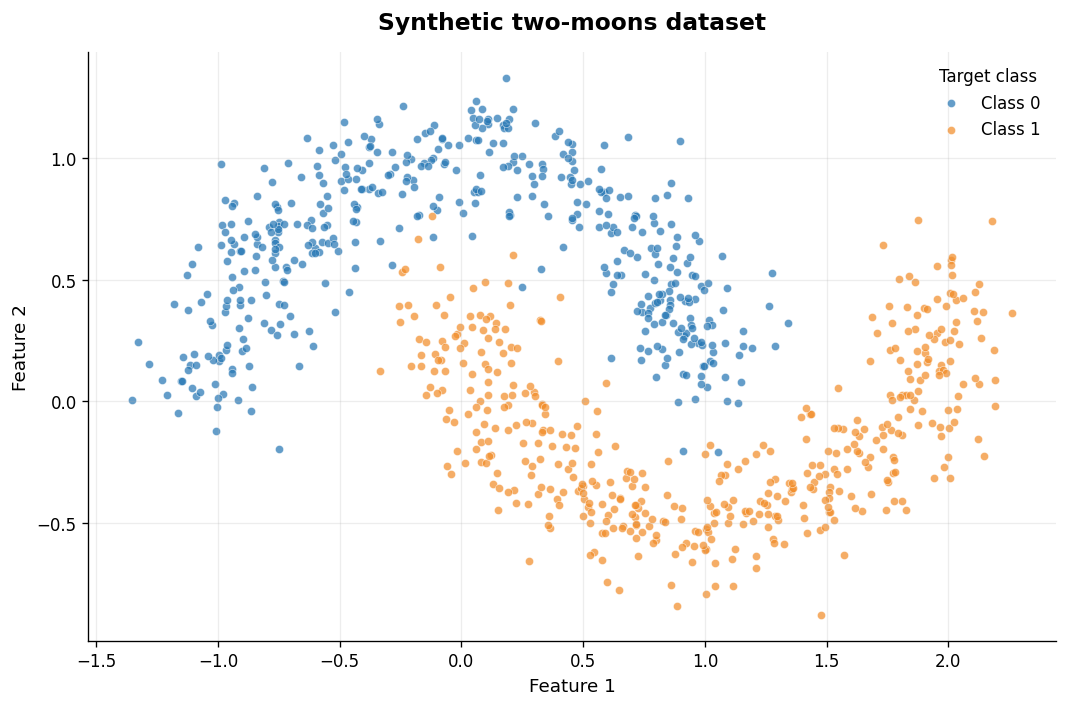

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for class_id, color, label in [(0, COLORS["blue"], "Class 0"), (1, COLORS["orange"], "Class 1")]:
    mask = y == class_id
    ax.scatter(X[mask, 0], X[mask, 1], s=24, alpha=0.72,
               c=color, edgecolors="white", linewidths=0.35, label=label)
ax.set_title("Synthetic two-moons dataset", pad=14)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(title="Target class")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()

**Observation:** the two classes curve around one another. A single linear layer followed by a threshold would struggle to represent this shape. Hidden layers and non-linear activations allow a multilayer perceptron (MLP) to learn a curved decision boundary.

## 6. Split the data and build data loaders

We will keep the test set separate until final evaluation:

- **70% training:** used to update model parameters.
- **15% validation:** used to monitor generalization while training.
- **15% test:** used once the model and training configuration are settled.

A `DataLoader` creates mini-batches. Mini-batch training is more memory-efficient than processing a large dataset in one pass and gives the optimizer multiple updates per epoch.

In [5]:
# Shuffle once, then assign disjoint indices to train, validation, and test sets.
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(X), generator=generator)

n_train = int(0.70 * len(X))
n_val = int(0.15 * len(X))
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

BATCH_SIZE = 32
train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

print(f"Training   : {len(X_train):>4} examples ({len(train_loader)} batches)")
print(f"Validation : {len(X_val):>4} examples")
print(f"Test       : {len(X_test):>4} examples")

Training   :  630 examples (20 batches)
Validation :  135 examples
Test       :  135 examples


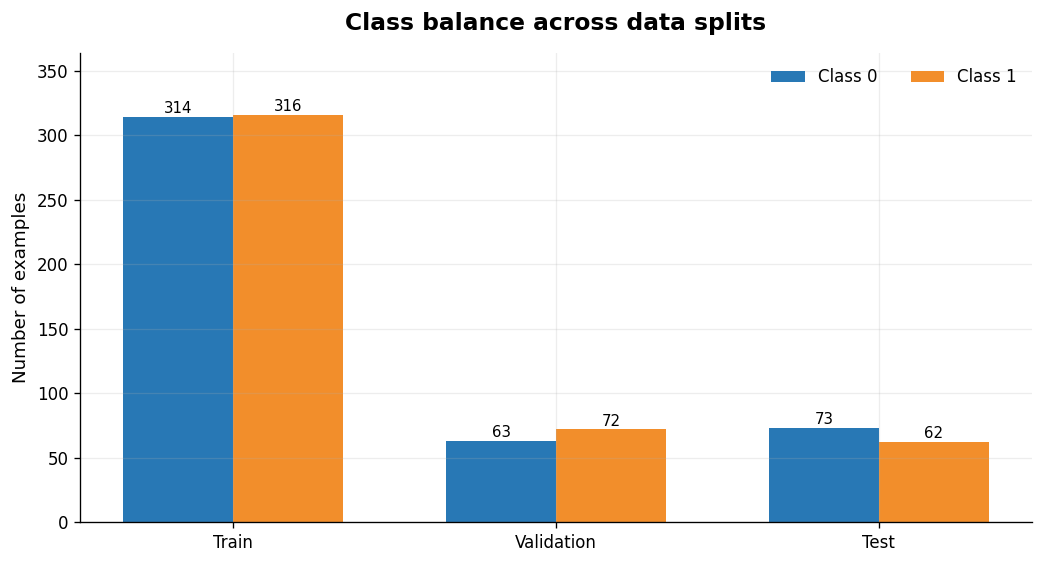

In [6]:
fig, ax = plt.subplots(figsize=(8.8, 4.8))
sets = [y_train, y_val, y_test]
set_names = ["Train", "Validation", "Test"]
width = 0.34
xpos = np.arange(len(set_names))
counts_0 = [int((target == 0).sum()) for target in sets]
counts_1 = [int((target == 1).sum()) for target in sets]
ax.bar(xpos - width/2, counts_0, width, label="Class 0", color=COLORS["blue"])
ax.bar(xpos + width/2, counts_1, width, label="Class 1", color=COLORS["orange"])
ax.set_xticks(xpos, set_names)
ax.set_ylabel("Number of examples")
ax.set_title("Class balance across data splits", pad=14)
ax.legend(ncol=2)
for i, value in enumerate(counts_0):
    ax.text(i - width/2, value + 3, str(value), ha="center", fontsize=9)
for i, value in enumerate(counts_1):
    ax.text(i + width/2, value + 3, str(value), ha="center", fontsize=9)
ax.set_ylim(0, max(counts_0 + counts_1) * 1.15)
fig.tight_layout()
plt.show()

## 7. Build the neural network with a custom `nn.Module`

We will use a compact MLP:

| Layer | Operation | Output features |
|---|---|---:|
| Input | two numeric features | 2 |
| Hidden 1 | `Linear(2, 32)` + ReLU | 32 |
| Hidden 2 | `Linear(32, 16)` + ReLU | 16 |
| Output | `Linear(16, 1)` | 1 logit |

**Important design choice:** the model returns a raw **logit**, not a sigmoid probability. We will pair it with `nn.BCEWithLogitsLoss`, which combines the sigmoid operation and binary cross-entropy in a numerically stable loss calculation.

In [7]:
class BinaryClassifier(nn.Module):
    """A small multilayer perceptron for binary classification."""

    def __init__(self, input_features: int, hidden_1: int = 32, hidden_2: int = 16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_features, hidden_1),
            nn.ReLU(),
            nn.Linear(hidden_1, hidden_2),
            nn.ReLU(),
            nn.Linear(hidden_2, 1),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        """Return one raw logit per example."""
        return self.network(features).squeeze(dim=1)

model = BinaryClassifier(input_features=X_train.shape[1]).to(DEVICE)
print(model)

BinaryClassifier(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


### Visual map of the architecture

The following diagram shows the flow of one batch through the network. The widths of the hidden layers indicate their number of units; the arrows show the order of computation.

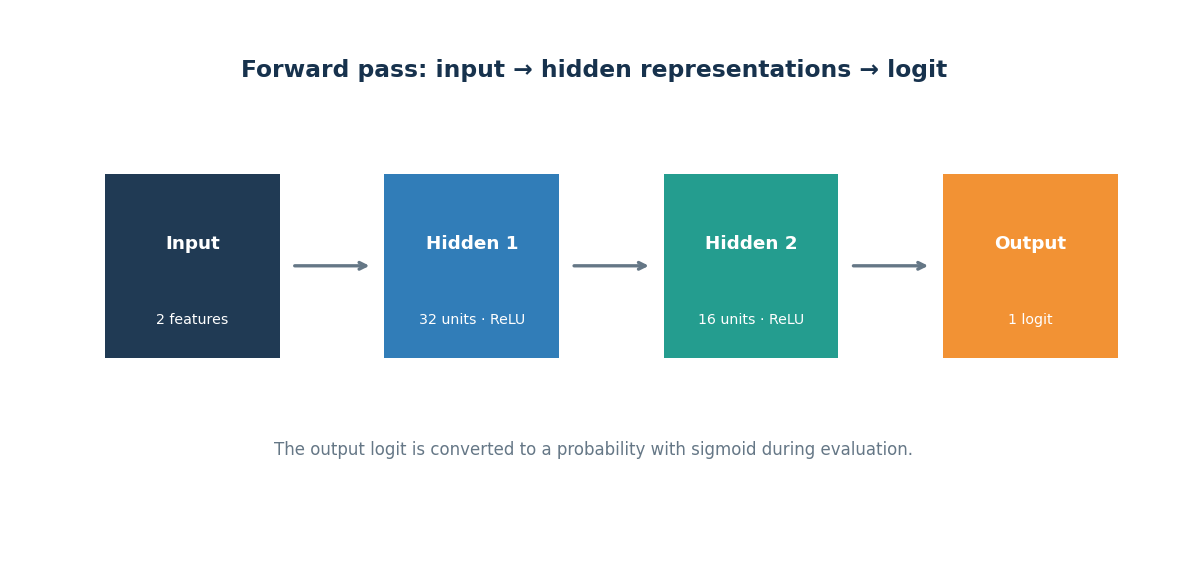

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.axis("off")
layer_specs = [
    (0.08, "Input", "2 features", COLORS["navy"]),
    (0.32, "Hidden 1", "32 units · ReLU", COLORS["blue"]),
    (0.56, "Hidden 2", "16 units · ReLU", COLORS["teal"]),
    (0.80, "Output", "1 logit", COLORS["orange"]),
]
for x_pos, title, subtitle, color in layer_specs:
    ax.add_patch(plt.Rectangle((x_pos, 0.36), 0.15, 0.34, transform=ax.transAxes,
                               facecolor=color, edgecolor="none", alpha=0.96))
    ax.text(x_pos + 0.075, 0.57, title, transform=ax.transAxes,
            ha="center", va="center", color="white", weight="bold", fontsize=11)
    ax.text(x_pos + 0.075, 0.43, subtitle, transform=ax.transAxes,
            ha="center", va="center", color="white", fontsize=8.5)
for start, end in [(0.23, 0.32), (0.47, 0.56), (0.71, 0.80)]:
    ax.annotate("", xy=(end - 0.01, 0.53), xytext=(start + 0.01, 0.53),
                xycoords=ax.transAxes, textcoords=ax.transAxes,
                arrowprops=dict(arrowstyle="->", lw=2, color=COLORS["gray"]))
ax.text(0.5, 0.88, "Forward pass: input → hidden representations → logit",
        transform=ax.transAxes, ha="center", fontsize=14, weight="bold", color=COLORS["navy"])
ax.text(0.5, 0.18, "The output logit is converted to a probability with sigmoid during evaluation.",
        transform=ax.transAxes, ha="center", fontsize=10, color=COLORS["gray"])
fig.tight_layout()
plt.show()

## 8. Inspect model parameters and verify the forward pass

PyTorch automatically registers parameters belonging to submodules assigned as attributes. This is why `model.parameters()` and `model.named_parameters()` can discover the weights and biases.

The earlier starter example attempted to access `model.linear2.weight`, but its layers were stored inside `model.network`. In this version, inspect parameters through `named_parameters()` or use the explicit path `model.network[0].weight` for the first linear layer.

In [9]:
print("Trainable parameter tensors:")
for name, parameter in model.named_parameters():
    print(f"{name:28s} shape={str(tuple(parameter.shape)):14s}  requires_grad={parameter.requires_grad}")

num_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
print(f"\nTotal trainable parameters: {num_parameters:,}")

# A quick forward-pass shape check (no training occurs here).
example_inputs = X_train[:5].to(DEVICE)
with torch.no_grad():
    example_logits = model(example_inputs)
print("\nInput batch shape :", tuple(example_inputs.shape))
print("Output shape      :", tuple(example_logits.shape))
print("Example logits    :", example_logits.cpu().numpy().round(3))

Trainable parameter tensors:
network.0.weight             shape=(32, 2)         requires_grad=True
network.0.bias               shape=(32,)           requires_grad=True
network.2.weight             shape=(16, 32)        requires_grad=True
network.2.bias               shape=(16,)           requires_grad=True
network.4.weight             shape=(1, 16)         requires_grad=True
network.4.bias               shape=(1,)            requires_grad=True

Total trainable parameters: 641

Input batch shape : (5, 2)
Output shape      : (5,)
Example logits    : [0.209 0.107 0.133 0.128 0.122]


### Optional: inspect the parameter count visually

This chart is based on the actual registered parameters in the model. Bias parameters are included.

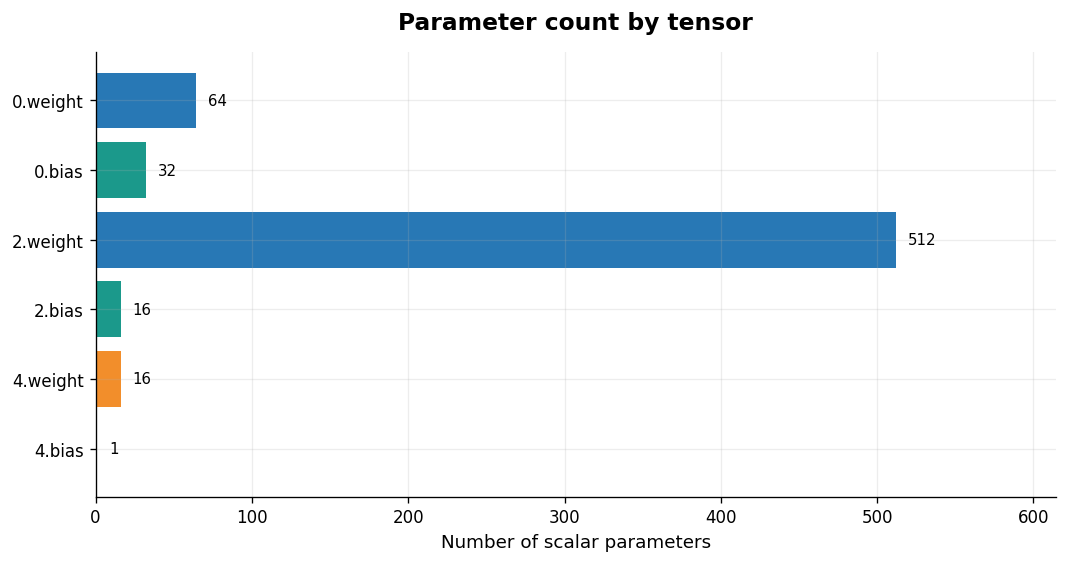

In [10]:
parameter_names = []
parameter_counts = []
for name, parameter in model.named_parameters():
    parameter_names.append(name.replace("network.", ""))
    parameter_counts.append(parameter.numel())

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(parameter_names, parameter_counts, color=[COLORS["blue"], COLORS["teal"], COLORS["blue"], COLORS["teal"], COLORS["orange"], COLORS["orange"]])
ax.invert_yaxis()
ax.set_xlabel("Number of scalar parameters")
ax.set_title("Parameter count by tensor", pad=14)
for bar, count in zip(bars, parameter_counts):
    ax.text(count + max(parameter_counts) * 0.015, bar.get_y() + bar.get_height()/2,
            f"{count:,}", va="center", fontsize=9)
ax.set_xlim(0, max(parameter_counts) * 1.2)
fig.tight_layout()
plt.show()

## 9. Configure the loss function and optimizer

### Loss: `nn.BCEWithLogitsLoss`

For each example, the model produces one logit. The target is a float in `{0, 1}`. `BCEWithLogitsLoss` is appropriate for binary classification with one output unit.

### Optimizer: `torch.optim.Adam`

Adam adapts update sizes using running estimates of gradient statistics. It is a practical starting point for many small neural-network experiments. The learning rate controls the size of parameter updates.

We will track **loss** and **accuracy** on both training and validation data. Accuracy is useful to interpret, while loss is more sensitive to confidence and is what the optimizer directly minimizes.

In [11]:
LEARNING_RATE = 0.01
NUM_EPOCHS = 180

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

print("Loss function:", criterion.__class__.__name__)
print("Optimizer    :", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)
print("Epochs       :", NUM_EPOCHS)

Loss function: BCEWithLogitsLoss
Optimizer    : Adam
Learning rate: 0.01
Epochs       : 180


## 10. Write the training and validation functions

A standard PyTorch training iteration follows this sequence:

1. `optimizer.zero_grad()` clears gradients from the previous batch.
2. `model(inputs)` performs the forward pass.
3. `criterion(logits, targets)` calculates the loss.
4. `loss.backward()` computes gradients with backpropagation.
5. `optimizer.step()` updates model parameters.

During validation, we use `model.eval()` and `torch.inference_mode()`. This disables gradient tracking and switches modules such as dropout/batch normalization into evaluation behavior. Our current MLP does not use those layers, but the pattern is important for larger models.

In [12]:
def calculate_accuracy(logits: torch.Tensor, targets: torch.Tensor) -> float:
    """Calculate binary accuracy from logits and 0/1 targets."""
    predictions = (torch.sigmoid(logits) >= 0.5).float()
    return (predictions == targets).float().mean().item()


def evaluate(model, features, targets, loss_fn):
    """Evaluate loss and accuracy without building a gradient graph."""
    model.eval()
    features = features.to(DEVICE)
    targets = targets.to(DEVICE)
    with torch.inference_mode():
        logits = model(features)
        loss = loss_fn(logits, targets)
        accuracy = calculate_accuracy(logits, targets)
    return loss.item(), accuracy


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Train for one complete pass over the training DataLoader."""
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for batch_features, batch_targets in loader:
        batch_features = batch_features.to(DEVICE)
        batch_targets = batch_targets.to(DEVICE)

        optimizer.zero_grad()
        logits = model(batch_features)
        loss = loss_fn(logits, batch_targets)
        loss.backward()
        optimizer.step()

        batch_size = batch_targets.size(0)
        total_loss += loss.item() * batch_size
        predictions = (torch.sigmoid(logits.detach()) >= 0.5).float()
        total_correct += (predictions == batch_targets).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples

## 11. Train the model

The training loop records one loss and accuracy value per epoch for both training and validation sets. The validation set is **not** used for gradient updates; it helps us spot whether progress on training data also generalizes to data the optimizer did not see.

In [13]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": [],
}

# Keep the parameters that achieve the best validation loss.
best_val_loss = float("inf")
best_val_epoch = 0
best_model_state = deepcopy(model.state_dict())

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_accuracy = evaluate(model, X_val, y_val, criterion)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_accuracy"].append(val_accuracy)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_epoch = epoch
        best_model_state = deepcopy(model.state_dict())

    if epoch == 1 or epoch % 30 == 0 or epoch == NUM_EPOCHS:
        print(
            f"Epoch {epoch:03d}/{NUM_EPOCHS} | "
            f"train loss: {train_loss:.4f} | val loss: {val_loss:.4f} | "
            f"train acc: {train_accuracy:.3f} | val acc: {val_accuracy:.3f}"
        )

# Restore the best validation checkpoint before final test evaluation.
model.load_state_dict(best_model_state)
print(f"\nRestored best validation checkpoint from epoch {best_val_epoch} (loss={best_val_loss:.4f}).")

Epoch 001/180 | train loss: 0.5470 | val loss: 0.3333 | train acc: 0.738 | val acc: 0.874
Epoch 030/180 | train loss: 0.0178 | val loss: 0.0554 | train acc: 0.992 | val acc: 0.978
Epoch 060/180 | train loss: 0.0155 | val loss: 0.0659 | train acc: 0.994 | val acc: 0.970
Epoch 090/180 | train loss: 0.0151 | val loss: 0.0621 | train acc: 0.994 | val acc: 0.978
Epoch 120/180 | train loss: 0.0171 | val loss: 0.0662 | train acc: 0.994 | val acc: 0.978
Epoch 150/180 | train loss: 0.0138 | val loss: 0.0650 | train acc: 0.994 | val acc: 0.978
Epoch 180/180 | train loss: 0.0143 | val loss: 0.0650 | train acc: 0.992 | val acc: 0.978

Restored best validation checkpoint from epoch 6 (loss=0.0391).


## 12. Visualize the learning process

A healthy learning curve usually shows decreasing loss. Training and validation curves should be interpreted together:

- If both losses remain high, the model may be underfitting or optimization may be ineffective.
- If training loss keeps falling while validation loss rises, the model may be overfitting.
- A small gap between training and validation performance is often a reassuring sign, although the right gap depends on the task and data.

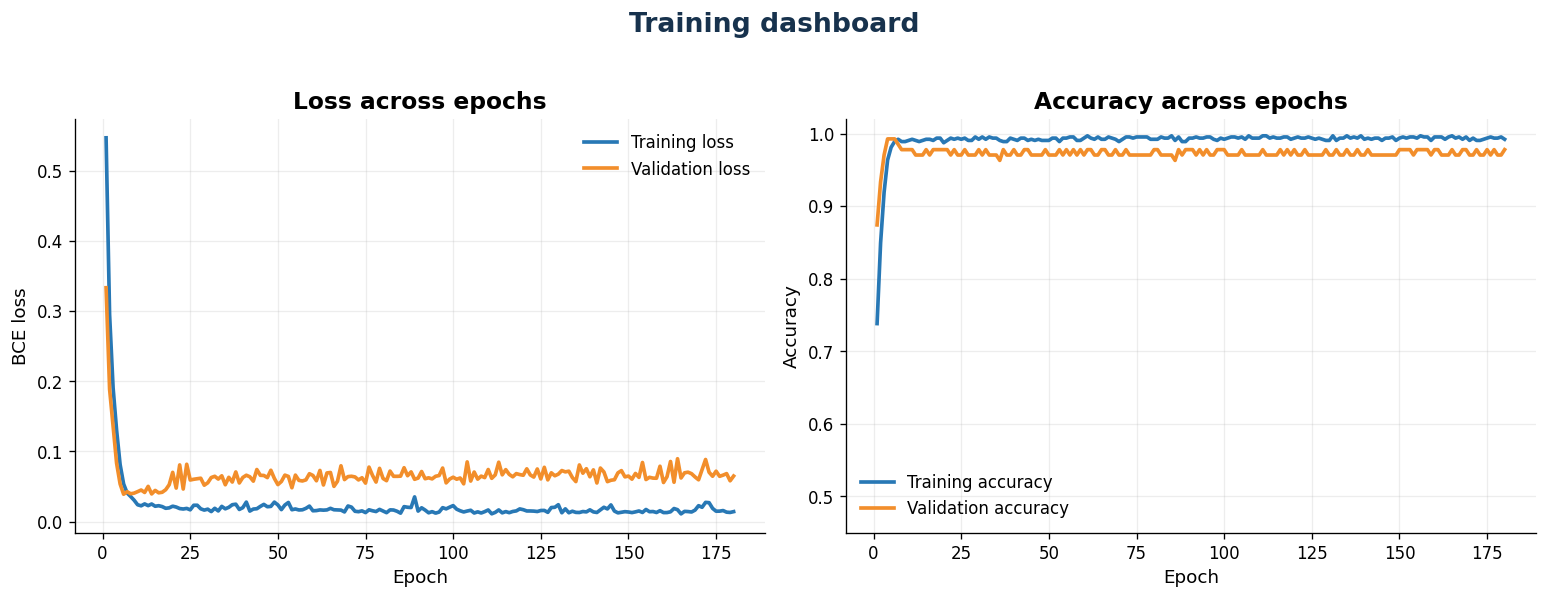

Lowest validation loss: 0.0391 at epoch 6


In [14]:
epoch_axis = np.arange(1, NUM_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(epoch_axis, history["train_loss"], label="Training loss", color=COLORS["blue"], linewidth=2.2)
axes[0].plot(epoch_axis, history["val_loss"], label="Validation loss", color=COLORS["orange"], linewidth=2.2)
axes[0].set_title("Loss across epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[0].legend()

axes[1].plot(epoch_axis, history["train_accuracy"], label="Training accuracy", color=COLORS["blue"], linewidth=2.2)
axes[1].plot(epoch_axis, history["val_accuracy"], label="Validation accuracy", color=COLORS["orange"], linewidth=2.2)
axes[1].set_title("Accuracy across epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.45, 1.02)
axes[1].legend()

fig.suptitle("Training dashboard", fontsize=16, fontweight="bold", color=COLORS["navy"], y=1.03)
fig.tight_layout()
plt.show()

print(f"Lowest validation loss: {best_val_loss:.4f} at epoch {best_val_epoch}")

## 13. Evaluate on the held-out test set

The test set was not used to update the weights or tune the training loop. It provides a final estimate of performance on unseen examples.

We report accuracy, precision, recall, and F1-score. For class `1`:

- **Precision:** of the examples predicted as class 1, how many truly belong to class 1?
- **Recall:** of the actual class 1 examples, how many did the model identify?
- **F1-score:** the harmonic mean of precision and recall.

The threshold is set to `0.5` for this demonstration. In real applications, choose a threshold based on the cost of false positives and false negatives.

In [15]:
model.eval()
with torch.inference_mode():
    test_logits = model(X_test.to(DEVICE)).cpu()
    test_probabilities = torch.sigmoid(test_logits).numpy()
    test_predictions = (test_probabilities >= 0.5).astype(int)

test_targets = y_test.numpy().astype(int)

tn = int(((test_predictions == 0) & (test_targets == 0)).sum())
fp = int(((test_predictions == 1) & (test_targets == 0)).sum())
fn = int(((test_predictions == 0) & (test_targets == 1)).sum())
tp = int(((test_predictions == 1) & (test_targets == 1)).sum())

accuracy = (tp + tn) / max(tp + tn + fp + fn, 1)
precision = tp / max(tp + fp, 1)
recall = tp / max(tp + fn, 1)
f1_score = 2 * precision * recall / max(precision + recall, 1e-12)

print("TEST SET METRICS")
print("----------------")
print(f"Accuracy  : {accuracy:.3f}")
print(f"Precision : {precision:.3f}")
print(f"Recall    : {recall:.3f}")
print(f"F1-score  : {f1_score:.3f}")
print(f"\nConfusion counts | TN={tn}, FP={fp}, FN={fn}, TP={tp}")

TEST SET METRICS
----------------
Accuracy  : 1.000
Precision : 1.000
Recall    : 1.000
F1-score  : 1.000

Confusion counts | TN=73, FP=0, FN=0, TP=62


## 14. Plot the learned decision boundary

A decision boundary shows where the model changes its predicted class. The background color represents the model's predicted probability for class 1; the contour at probability `0.5` is the decision boundary.

This is one of the most useful plots for understanding a classifier with two input features. It shows *where* the model succeeds or struggles, not just one aggregate score.

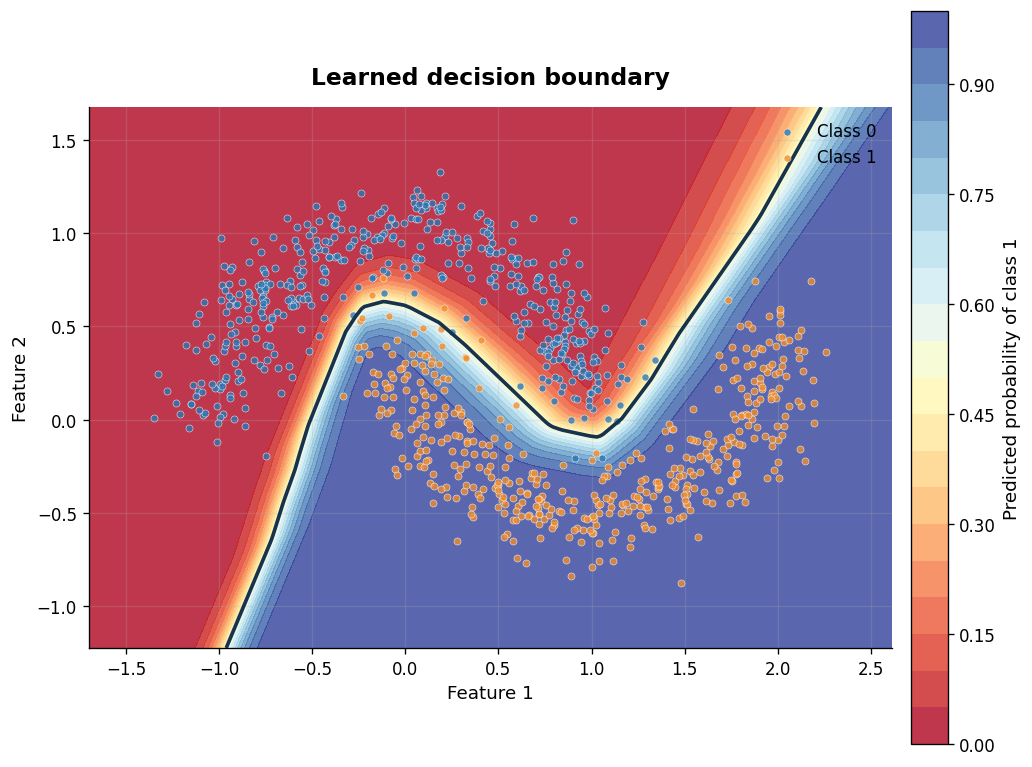

In [16]:
@torch.inference_mode()
def predict_probability_grid(model, x_min, x_max, y_min, y_max, resolution=260):
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, resolution),
        np.linspace(y_min, y_max, resolution),
    )
    grid = np.column_stack((xx.ravel(), yy.ravel())).astype(np.float32)
    logits = model(torch.from_numpy(grid).to(DEVICE))
    probabilities = torch.sigmoid(logits).cpu().numpy().reshape(xx.shape)
    return xx, yy, probabilities

x_margin, y_margin = 0.35, 0.35
x_min, x_max = X[:, 0].min().item() - x_margin, X[:, 0].max().item() + x_margin
y_min, y_max = X[:, 1].min().item() - y_margin, X[:, 1].max().item() + y_margin
xx, yy, probability_grid = predict_probability_grid(model, x_min, x_max, y_min, y_max)

fig, ax = plt.subplots(figsize=(9, 6.5))
contour = ax.contourf(xx, yy, probability_grid, levels=np.linspace(0, 1, 21), cmap="RdYlBu", alpha=0.82)
ax.contour(xx, yy, probability_grid, levels=[0.5], colors=COLORS["navy"], linewidths=2.2)
for class_id, color, label in [(0, COLORS["blue"], "Class 0"), (1, COLORS["orange"], "Class 1")]:
    mask = y.numpy() == class_id
    ax.scatter(X.numpy()[mask, 0], X.numpy()[mask, 1], s=18, c=color,
               edgecolors="white", linewidths=0.35, alpha=0.78, label=label)
colorbar = fig.colorbar(contour, ax=ax, pad=0.02)
colorbar.set_label("Predicted probability of class 1")
ax.set_title("Learned decision boundary", pad=14)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend(loc="upper right")
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 15. Confusion matrix and ROC curve

The confusion matrix separates correct predictions from two types of error. The ROC curve shows the trade-off between true-positive rate and false-positive rate as the classification threshold changes.

For the ROC curve, we calculate rates at a sequence of thresholds. The area under the curve (AUC) summarizes ranking performance: a value closer to 1 indicates stronger separation between the positive and negative classes.

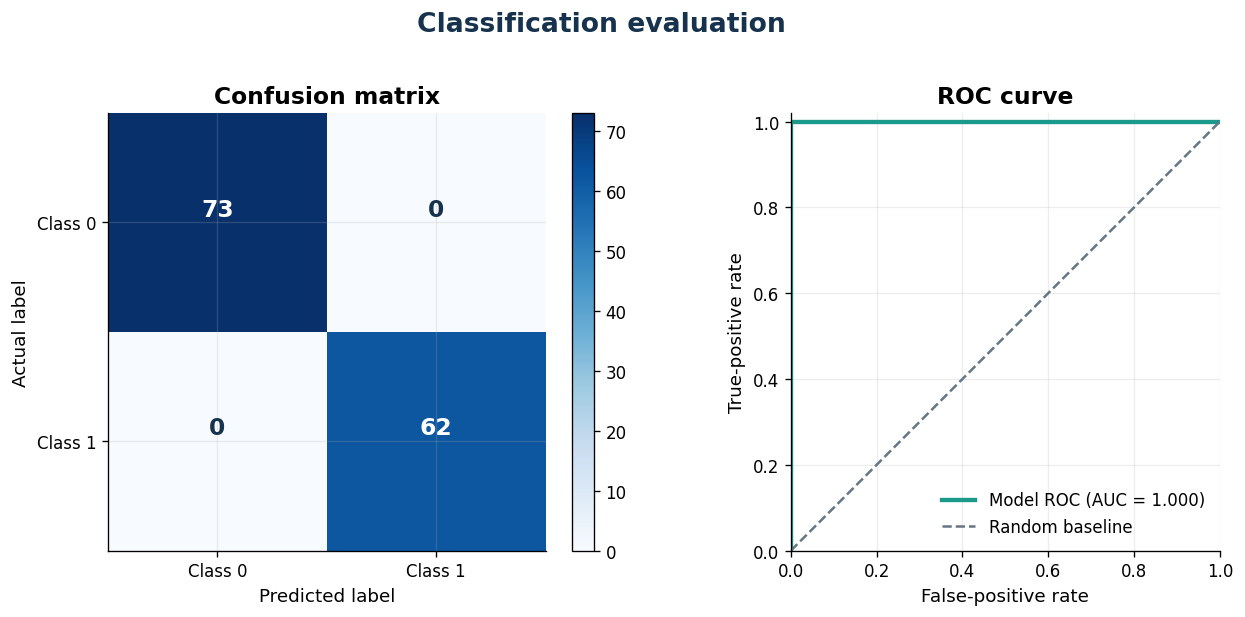

ROC-AUC: 1.000


In [17]:
# Confusion matrix, with rows = actual class and columns = predicted class.
confusion = np.array([[tn, fp], [fn, tp]])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

image = axes[0].imshow(confusion, cmap="Blues")
axes[0].set_title("Confusion matrix")
axes[0].set_xlabel("Predicted label")
axes[0].set_ylabel("Actual label")
axes[0].set_xticks([0, 1], ["Class 0", "Class 1"])
axes[0].set_yticks([0, 1], ["Class 0", "Class 1"])
for row in range(2):
    for col in range(2):
        text_color = "white" if confusion[row, col] > confusion.max() * 0.55 else COLORS["navy"]
        axes[0].text(col, row, f"{confusion[row, col]}\n", ha="center", va="center",
                     color=text_color, fontsize=14, fontweight="bold")
fig.colorbar(image, ax=axes[0], fraction=0.046, pad=0.04)

thresholds = np.linspace(1.0, 0.0, 201)
tpr_values, fpr_values = [], []
for threshold in thresholds:
    pred = (test_probabilities >= threshold).astype(int)
    tp_i = np.sum((pred == 1) & (test_targets == 1))
    fp_i = np.sum((pred == 1) & (test_targets == 0))
    fn_i = np.sum((pred == 0) & (test_targets == 1))
    tn_i = np.sum((pred == 0) & (test_targets == 0))
    tpr_values.append(tp_i / max(tp_i + fn_i, 1))
    fpr_values.append(fp_i / max(fp_i + tn_i, 1))

# Sort by false-positive rate before numerical integration.
order = np.argsort(fpr_values)
fpr_sorted = np.asarray(fpr_values)[order]
tpr_sorted = np.asarray(tpr_values)[order]
roc_auc = float(np.trapezoid(tpr_sorted, fpr_sorted))

axes[1].plot(fpr_sorted, tpr_sorted, color=COLORS["teal"], linewidth=2.6,
             label=f"Model ROC (AUC = {roc_auc:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color=COLORS["gray"], label="Random baseline")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].set_aspect("equal", adjustable="box")
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False-positive rate")
axes[1].set_ylabel("True-positive rate")
axes[1].legend(loc="lower right")

fig.suptitle("Classification evaluation", fontsize=16, fontweight="bold", color=COLORS["navy"], y=1.02)
fig.tight_layout()
plt.show()
print(f"ROC-AUC: {roc_auc:.3f}")

## 16. Inspect what the network learned

A parameter histogram is not a complete explanation of a neural network, but it is a useful diagnostic. It can reveal unexpectedly large values, unusual distributions, or parameters that remain clustered near zero.

Remember that each layer's weights work together. Do not interpret an individual weight as a causal feature effect without a method designed for that purpose.

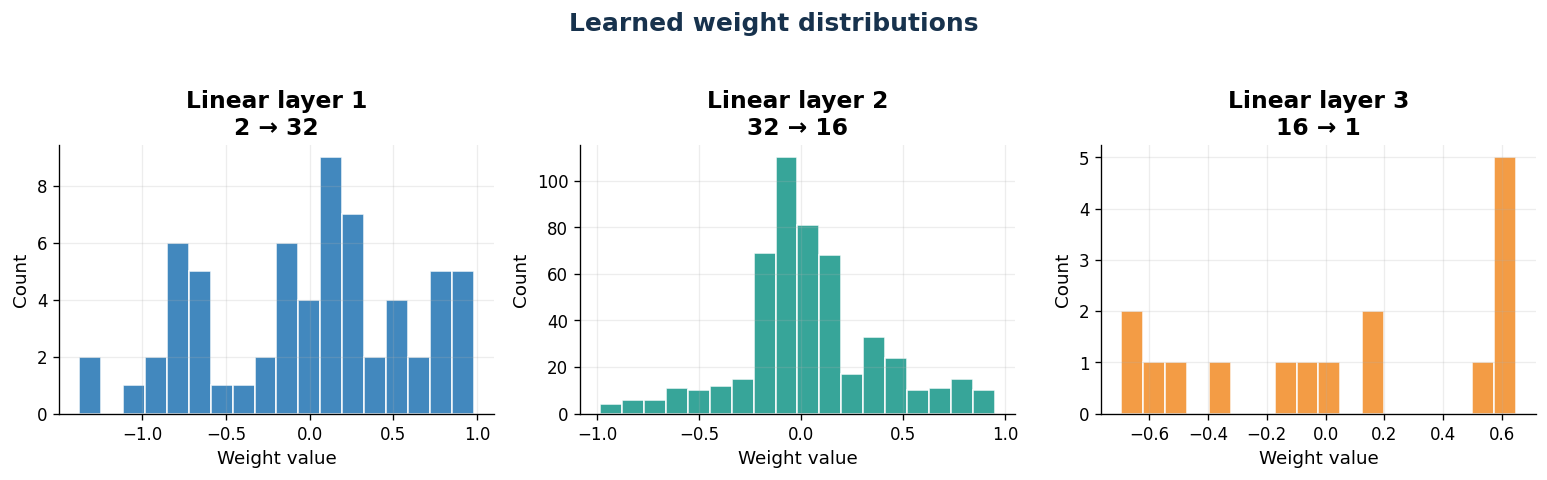

In [18]:
linear_layers = [module for module in model.modules() if isinstance(module, nn.Linear)]
fig, axes = plt.subplots(1, len(linear_layers), figsize=(13, 3.8))
for index, (layer, ax) in enumerate(zip(linear_layers, axes)):
    weights = layer.weight.detach().cpu().numpy().ravel()
    ax.hist(weights, bins=18, color=[COLORS["blue"], COLORS["teal"], COLORS["orange"]][index],
            alpha=0.88, edgecolor="white")
    ax.set_title(f"Linear layer {index + 1}\n{layer.in_features} → {layer.out_features}")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Count")
fig.suptitle("Learned weight distributions", fontsize=15, fontweight="bold", color=COLORS["navy"], y=1.04)
fig.tight_layout()
plt.show()

## 17. Make predictions on new examples

For inference, switch the model to evaluation mode and disable gradient tracking. The model returns logits; apply sigmoid to obtain probabilities. A threshold then converts probabilities into class labels.

The two sample points below are illustrative. Their labels are unknown to the model at prediction time.

In [19]:
new_examples = torch.tensor([
    [-0.65, 0.55],
    [1.45, 0.35],
    [0.20, 0.10],
], dtype=torch.float32).to(DEVICE)

model.eval()
with torch.inference_mode():
    new_logits = model(new_examples)
    new_probabilities = torch.sigmoid(new_logits)
    new_classes = (new_probabilities >= 0.5).int()

for index, (point, probability, predicted_class) in enumerate(
    zip(new_examples.cpu(), new_probabilities.cpu(), new_classes.cpu()), start=1
):
    print(
        f"Example {index}: features={point.tolist()} | "
        f"P(class 1)={probability.item():.3f} | predicted class={predicted_class.item()}"
    )

Example 1: features=[-0.6499999761581421, 0.550000011920929] | P(class 1)=0.002 | predicted class=0
Example 2: features=[1.4500000476837158, 0.3499999940395355] | P(class 1)=0.617 | predicted class=1
Example 3: features=[0.20000000298023224, 0.10000000149011612] | P(class 1)=0.958 | predicted class=1


## 18. Save and reload the model

The recommended PyTorch pattern is to save the model's **`state_dict`**. It stores the learned parameters and buffers, while the model class defines the architecture. When loading, instantiate the same architecture first, then load the state dictionary.

The checkpoint below also stores a small amount of metadata to make the file easier to identify later.

In [20]:
checkpoint_path = Path("pytorch_nn_module_checkpoint.pth")

checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_features": X_train.shape[1],
    "hidden_1": 32,
    "hidden_2": 16,
    "decision_threshold": 0.5,
    "seed": SEED,
}
torch.save(checkpoint, checkpoint_path)
print(f"Saved checkpoint: {checkpoint_path.resolve()}")

# Recreate the model architecture, then restore its learned parameters.
loaded_checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
reloaded_model = BinaryClassifier(
    input_features=loaded_checkpoint["input_features"],
    hidden_1=loaded_checkpoint["hidden_1"],
    hidden_2=loaded_checkpoint["hidden_2"],
).to(DEVICE)
reloaded_model.load_state_dict(loaded_checkpoint["model_state_dict"])
reloaded_model.eval()

with torch.inference_mode():
    original_output = model(X_test[:10].to(DEVICE))
    reloaded_output = reloaded_model(X_test[:10].to(DEVICE))

max_difference = (original_output - reloaded_output).abs().max().item()
print(f"Maximum output difference after reloading: {max_difference:.10f}")

Saved checkpoint: /content/pytorch_nn_module_checkpoint.pth
Maximum output difference after reloading: 0.0000000000


## 19. Common mistakes and debugging checklist

| Mistake | Why it causes trouble | Better practice |
|---|---|---|
| Forgetting `super().__init__()` | Submodules are not initialized correctly | Call it first inside `__init__()` |
| Calling `model.forward(x)` directly | Bypasses the normal module call machinery | Use `model(x)` |
| Wrong input feature count | Matrix dimensions do not match | Check `x.shape` and the first `Linear` layer |
| Applying sigmoid before `BCEWithLogitsLoss` | The loss expects raw logits | Return logits; apply sigmoid for probabilities |
| Forgetting `zero_grad()` | Gradients accumulate across batches | Clear gradients before each backward pass |
| Forgetting `model.eval()` at evaluation time | Some layers behave differently during evaluation | Switch to evaluation mode before validation/inference |
| Tracking gradients during evaluation | Wastes memory and computation | Use `torch.inference_mode()` |
| Evaluating only on training data | Gives an optimistic performance estimate | Keep validation and test data separate |
| Accessing a layer by the wrong attribute | The layer may be nested inside `Sequential` | Inspect `model`, `named_modules()`, or `named_parameters()` |

### Quick debugging routine

```python
print(model)
print("Input:", x.shape)
for name, parameter in model.named_parameters():
    print(name, parameter.shape)
```

## 20. Practice exercises

Try these in a copy of the notebook. Predict what will change before running the code.

### Exercise 1 — Change the network capacity

Change the hidden dimensions from `32 → 16` to `64 → 32`. Compare the parameter count, training curve, and test metrics.

### Exercise 2 — Change the learning rate

Try `0.001`, `0.01`, and `0.05`. Plot the validation loss for each run. Which value converges smoothly?

### Exercise 3 — Add regularization

Add `nn.Dropout(p=0.2)` after a hidden activation. Compare training and validation curves. Explain whether the gap changes.

### Exercise 4 — Change the decision threshold

Evaluate thresholds such as `0.35`, `0.50`, and `0.65`. Compare precision and recall. Explain which error type becomes more common.

### Exercise 5 — Add a third hidden layer

Create a deeper MLP and compare it with the original. Does a larger model always improve test performance?

### Exercise 6 — Replace Adam

Use `torch.optim.SGD` with a suitable learning rate. Compare convergence speed and stability.

## 21. Create a reusable custom `Dataset`

The earlier notebook used `TensorDataset`, which is convenient when the features and labels are already tensors. In real projects, a custom `Dataset` is useful when data must be loaded, transformed, validated, or sampled in a custom way.

A map-style dataset implements `__len__()` and `__getitem__()`. `DataLoader` then handles batching and shuffling.

In [21]:
from torch.utils.data import Dataset

class TwoMoonsDataset(Dataset):
    """Small map-style dataset backed by feature and target tensors."""
    def __init__(self, features: torch.Tensor, targets: torch.Tensor):
        if len(features) != len(targets):
            raise ValueError("Features and targets must contain the same number of rows.")
        self.features = features.float()
        self.targets = targets.float()

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, index):
        return self.features[index], self.targets[index]

train_dataset = TwoMoonsDataset(X_train, y_train)
custom_train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

print(f"Dataset length : {len(train_dataset)}")
print(f"Number batches : {len(custom_train_loader)}")
feature_batch, target_batch = next(iter(custom_train_loader))
print(f"Feature batch  : {tuple(feature_batch.shape)}")
print(f"Target batch   : {tuple(target_batch.shape)}")
print(f"Feature dtype  : {feature_batch.dtype} | Target dtype: {target_batch.dtype}")

Dataset length : 630
Number batches : 10
Feature batch  : (64, 2)
Target batch   : (64,)
Feature dtype  : torch.float32 | Target dtype: torch.float32


## 22. Compose models from reusable building blocks

A custom `nn.Module` does not need to represent the entire network. It can represent one reusable block. This is especially useful when architectures grow or when the same block appears multiple times.

In [22]:
class DenseBlock(nn.Module):
    """Linear transformation followed by normalization and activation."""
    def __init__(self, in_features: int, out_features: int, dropout: float = 0.0):
        super().__init__()
        layers = [nn.Linear(in_features, out_features), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(p=dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class ModularClassifier(nn.Module):
    def __init__(self, input_features: int, widths=(32, 16), dropout=0.0):
        super().__init__()
        blocks = []
        previous_width = input_features
        for width in widths:
            blocks.append(DenseBlock(previous_width, width, dropout=dropout))
            previous_width = width
        self.feature_extractor = nn.Sequential(*blocks)
        self.output_layer = nn.Linear(previous_width, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        representation = self.feature_extractor(x)
        return self.output_layer(representation).squeeze(1)

modular_model = ModularClassifier(input_features=2, widths=(32, 16)).to(DEVICE)
with torch.inference_mode():
    modular_logits = modular_model(X_train[:12].to(DEVICE))
print(modular_model)
print("Output shape:", tuple(modular_logits.shape))
print("Trainable parameters:", sum(p.numel() for p in modular_model.parameters() if p.requires_grad))

ModularClassifier(
  (feature_extractor): Sequential(
    (0): DenseBlock(
      (block): Sequential(
        (0): Linear(in_features=2, out_features=32, bias=True)
        (1): ReLU()
      )
    )
    (1): DenseBlock(
      (block): Sequential(
        (0): Linear(in_features=32, out_features=16, bias=True)
        (1): ReLU()
      )
    )
  )
  (output_layer): Linear(in_features=16, out_features=1, bias=True)
)
Output shape: (12,)
Trainable parameters: 641


## 23. Understand parameters, buffers, and the `state_dict`

- A **parameter** is a learnable tensor optimized by gradient descent.
- A **buffer** is a tensor stored in the module but not optimized by the optimizer. Running statistics in batch normalization are a common example.
- A module's `state_dict()` contains both parameters and persistent buffers.

In [23]:
class ModuleStateDemo(nn.Module):
    def __init__(self, input_features=2):
        super().__init__()
        self.linear = nn.Linear(input_features, 4)
        self.scale = nn.Parameter(torch.ones(4))
        self.register_buffer("inference_threshold", torch.tensor(0.5))

    def forward(self, x):
        return self.linear(x) * self.scale

state_demo = ModuleStateDemo().to(DEVICE)
print("Named parameters:")
for name, value in state_demo.named_parameters():
    print(f"  {name:24s} shape={tuple(value.shape)}")
print("\nNamed buffers:")
for name, value in state_demo.named_buffers():
    print(f"  {name:24s} value={value.detach().cpu().tolist()}")
print("\nstate_dict keys:", list(state_demo.state_dict().keys()))

Named parameters:
  scale                    shape=(4,)
  linear.weight            shape=(4, 2)
  linear.bias              shape=(4,)

Named buffers:
  inference_threshold      value=0.5

state_dict keys: ['scale', 'inference_threshold', 'linear.weight', 'linear.bias']


## 24. Observe why `model.train()` and `model.eval()` matter

Dropout randomly zeroes some activations during training. During evaluation it is disabled. Batch normalization also changes behavior between training and evaluation. The next cell demonstrates dropout directly.

In [24]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(2, 32), nn.ReLU(), nn.Dropout(p=0.50), nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.layers(x)

dropout_demo = DropoutDemo().to(DEVICE)
fixed_batch = X_train[:64].to(DEVICE)

dropout_demo.train()
with torch.no_grad():
    train_output_1 = dropout_demo(fixed_batch)
    train_output_2 = dropout_demo(fixed_batch)

dropout_demo.eval()
with torch.no_grad():
    eval_output_1 = dropout_demo(fixed_batch)
    eval_output_2 = dropout_demo(fixed_batch)

train_difference = (train_output_1 - train_output_2).abs().mean().item()
eval_difference = (eval_output_1 - eval_output_2).abs().mean().item()
print(f"Mean difference in train mode: {train_difference:.6f}")
print(f"Mean difference in eval mode : {eval_difference:.6f}")
print("Expected behavior: train-mode outputs vary because dropout is active; eval-mode outputs are repeatable.")

Mean difference in train mode: 0.204280
Mean difference in eval mode : 0.000000
Expected behavior: train-mode outputs vary because dropout is active; eval-mode outputs are repeatable.


## 25. Capture intermediate activations with forward hooks

Hooks are useful for debugging tensor shapes and inspecting intermediate representations. A forward hook runs after a selected module has produced its output. Always remove hooks after collecting the information.

hidden_1_relu    shape=(128, 32) | mean=0.2672 | std=0.4350 | zero_fraction=0.610
hidden_2_relu    shape=(128, 16) | mean=0.8144 | std=1.0681 | zero_fraction=0.456


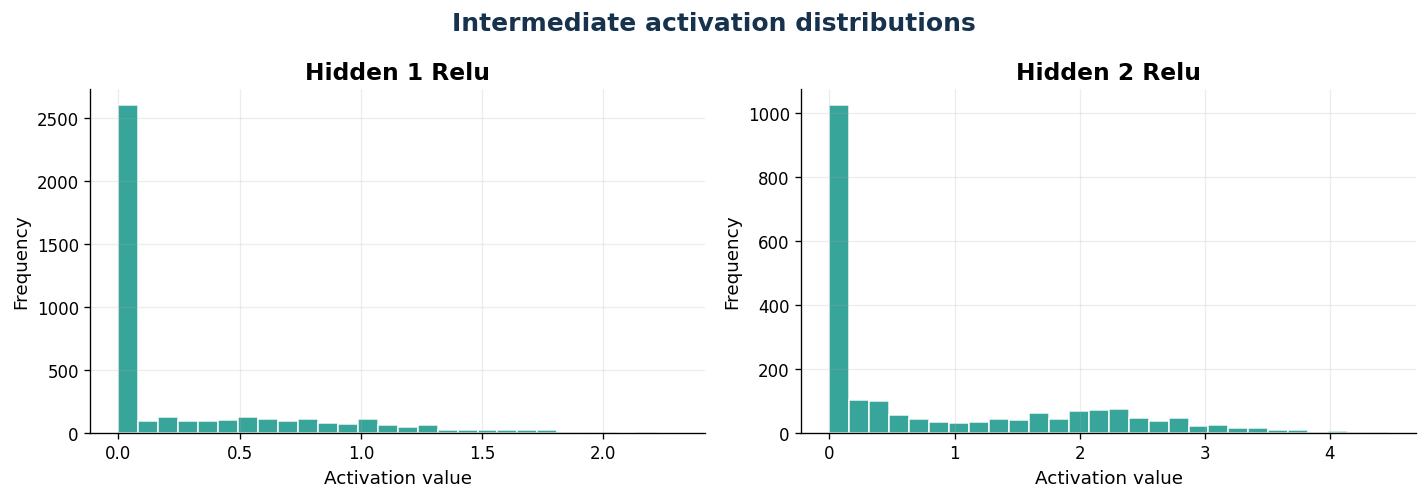

In [25]:
activation_cache = {}
hook_handles = []

def make_activation_hook(layer_name):
    def capture_activation(module, inputs, output):
        activation_cache[layer_name] = output.detach().cpu()
    return capture_activation

# The main model uses nn.Sequential: Linear, ReLU, Linear, ReLU, Linear.
hook_handles.append(model.network[1].register_forward_hook(make_activation_hook("hidden_1_relu")))
hook_handles.append(model.network[3].register_forward_hook(make_activation_hook("hidden_2_relu")))

model.eval()
with torch.inference_mode():
    _ = model(X_train[:128].to(DEVICE))

for handle in hook_handles:
    handle.remove()

for layer_name, activation in activation_cache.items():
    print(f"{layer_name:16s} shape={tuple(activation.shape)} | mean={activation.mean():.4f} | std={activation.std():.4f} | zero_fraction={(activation == 0).float().mean():.3f}")

fig, axes = plt.subplots(1, len(activation_cache), figsize=(12, 4.2))
for ax, (layer_name, activation) in zip(axes, activation_cache.items()):
    ax.hist(activation.numpy().ravel(), bins=28, color=COLORS["teal"], alpha=0.88, edgecolor="white")
    ax.set_title(layer_name.replace("_", " ").title())
    ax.set_xlabel("Activation value")
    ax.set_ylabel("Frequency")
fig.suptitle("Intermediate activation distributions", color=COLORS["navy"], fontweight="bold", fontsize=15)
fig.tight_layout()
plt.show()

## 26. Inspect gradient flow after backpropagation

`loss.backward()` computes gradients and stores them in each parameter's `.grad` attribute. This cell performs one training step on a fresh model and visualizes the gradient magnitude for each parameter tensor.

network.0.weight          gradient norm = 0.027591
network.0.bias            gradient norm = 0.012535
network.2.weight          gradient norm = 0.135721
network.2.bias            gradient norm = 0.028040
network.4.weight          gradient norm = 0.038104
network.4.bias            gradient norm = 0.029920


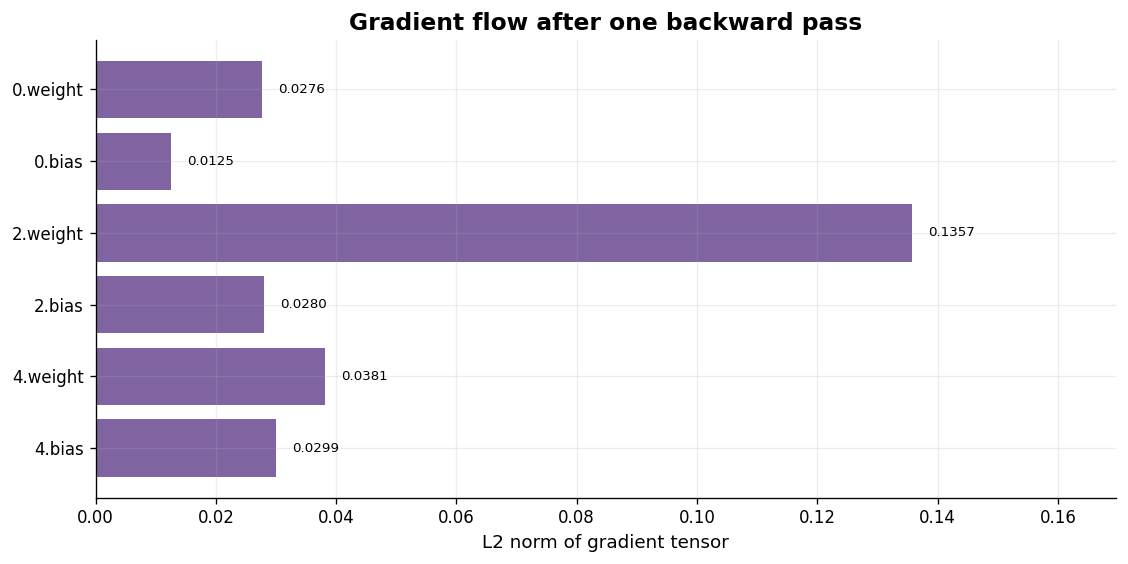

In [26]:
gradient_probe = BinaryClassifier(input_features=2).to(DEVICE)
gradient_probe.train()
probe_features, probe_targets = next(iter(train_loader))
probe_features = probe_features.to(DEVICE)
probe_targets = probe_targets.to(DEVICE)

probe_logits = gradient_probe(probe_features)
probe_loss = criterion(probe_logits, probe_targets)
gradient_probe.zero_grad(set_to_none=True)
probe_loss.backward()

gradient_names, gradient_norms = [], []
for name, parameter in gradient_probe.named_parameters():
    if parameter.grad is not None:
        gradient_names.append(name.replace("network.", ""))
        gradient_norms.append(parameter.grad.detach().norm().item())
        print(f"{name:25s} gradient norm = {parameter.grad.norm().item():.6f}")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.barh(gradient_names, gradient_norms, color=COLORS["purple"])
ax.invert_yaxis()
ax.set_xlabel("L2 norm of gradient tensor")
ax.set_title("Gradient flow after one backward pass")
for bar, value in zip(bars, gradient_norms):
    ax.text(value + max(gradient_norms) * 0.02, bar.get_y() + bar.get_height()/2, f"{value:.4f}", va="center", fontsize=8)
ax.set_xlim(0, max(gradient_norms) * 1.25 + 1e-9)
fig.tight_layout()
plt.show()

## 27. Compare default and explicit weight initialization

Initialization controls the starting scale of activations and gradients. PyTorch layers already have sensible defaults. The following comparison shows the distribution of a first-layer weight tensor before training, then applies Kaiming initialization explicitly.

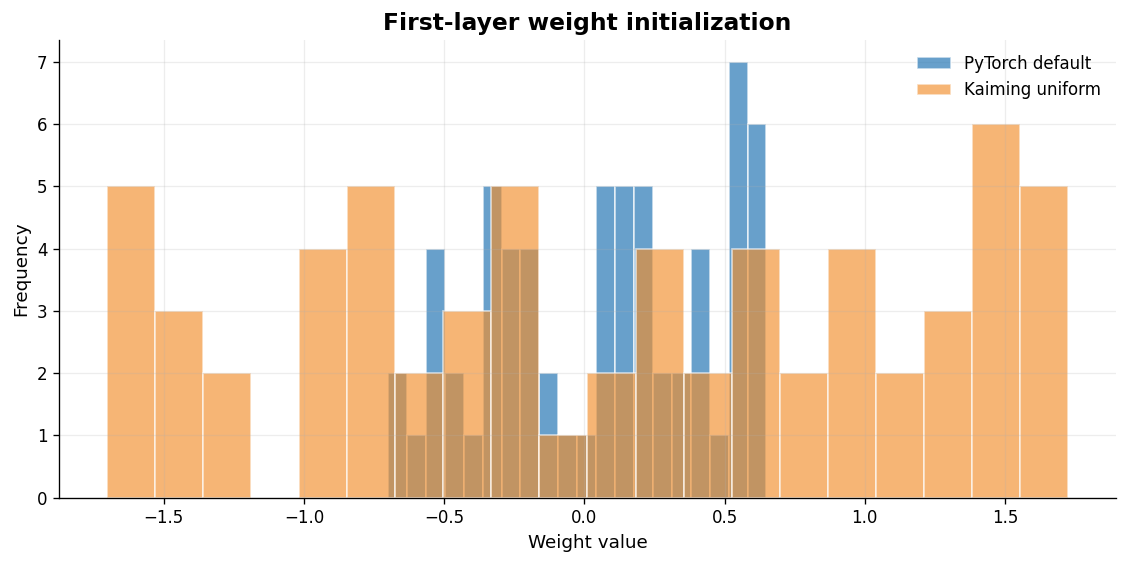

Default std : 0.3946
Kaiming std : 1.0529


In [27]:
torch.manual_seed(SEED)
default_init_model = BinaryClassifier(input_features=2).to(DEVICE)

torch.manual_seed(SEED)
kaiming_init_model = BinaryClassifier(input_features=2).to(DEVICE)

def apply_kaiming_initialization(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight, nonlinearity="relu")
        if module.bias is not None:
            nn.init.zeros_(module.bias)

kaiming_init_model.apply(apply_kaiming_initialization)

def first_layer_weights(candidate):
    return candidate.network[0].weight.detach().cpu().numpy().ravel()

default_weights = first_layer_weights(default_init_model)
kaiming_weights = first_layer_weights(kaiming_init_model)

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hist(default_weights, bins=20, alpha=0.70, label="PyTorch default", color=COLORS["blue"], edgecolor="white")
ax.hist(kaiming_weights, bins=20, alpha=0.65, label="Kaiming uniform", color=COLORS["orange"], edgecolor="white")
ax.set_title("First-layer weight initialization")
ax.set_xlabel("Weight value")
ax.set_ylabel("Frequency")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Default std : {default_weights.std():.4f}")
print(f"Kaiming std : {kaiming_weights.std():.4f}")

## 28. Compare Adam and SGD with momentum

Optimizers update parameters differently. This controlled experiment starts both models from the same initial weights and trains them on the same training data. Validation loss is recorded after each epoch.

Adam               | final val loss=0.0611 | val accuracy=0.970
SGD + momentum     | final val loss=0.1041 | val accuracy=0.970


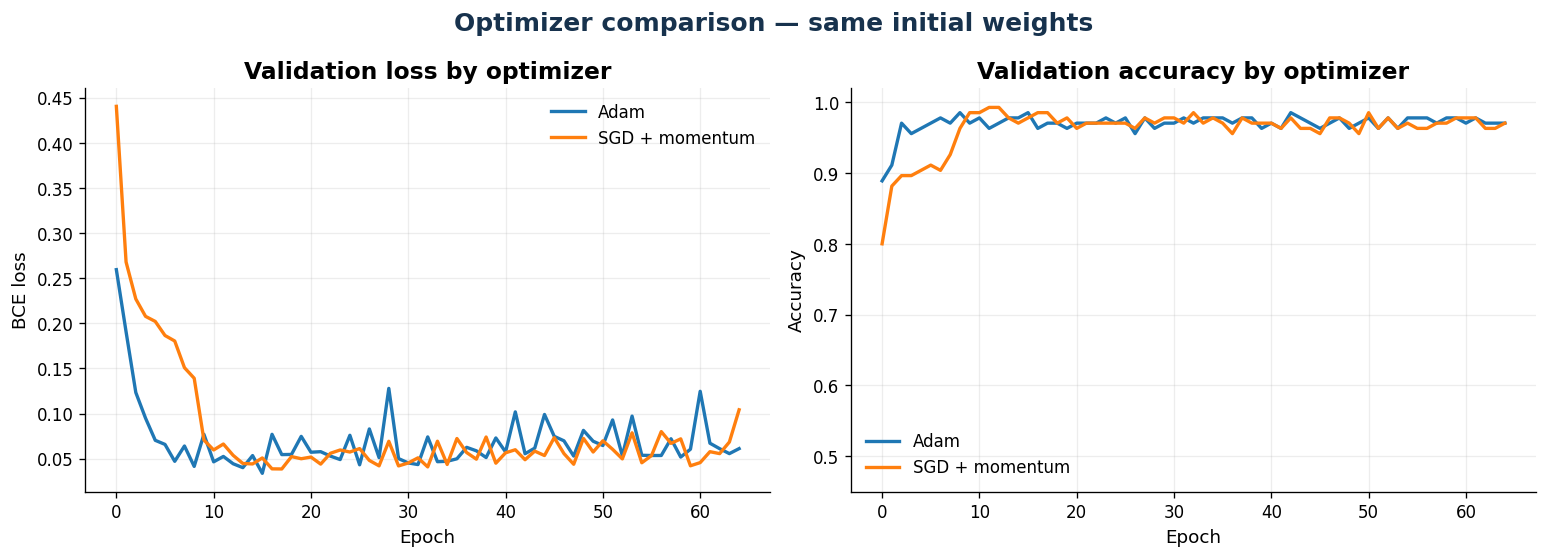

In [28]:
comparison_seed_model = BinaryClassifier(input_features=2)
common_initial_state = deepcopy(comparison_seed_model.state_dict())
optimizer_histories = {}
optimizer_models = {}
OPTIMIZER_EPOCHS = 65

optimizer_settings = {
    "Adam": (torch.optim.Adam, {"lr": 0.01}),
    "SGD + momentum": (torch.optim.SGD, {"lr": 0.035, "momentum": 0.90}),
}

for optimizer_name, (optimizer_class, optimizer_kwargs) in optimizer_settings.items():
    candidate = BinaryClassifier(input_features=2).to(DEVICE)
    candidate.load_state_dict(common_initial_state)
    candidate_optimizer = optimizer_class(candidate.parameters(), **optimizer_kwargs)
    candidate_history = {"train_loss": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(OPTIMIZER_EPOCHS):
        train_loss_value, _ = train_one_epoch(candidate, train_loader, criterion, candidate_optimizer)
        val_loss_value, val_accuracy_value = evaluate(candidate, X_val, y_val, criterion)
        candidate_history["train_loss"].append(train_loss_value)
        candidate_history["val_loss"].append(val_loss_value)
        candidate_history["val_accuracy"].append(val_accuracy_value)

    optimizer_histories[optimizer_name] = candidate_history
    optimizer_models[optimizer_name] = candidate
    print(f"{optimizer_name:18s} | final val loss={candidate_history['val_loss'][-1]:.4f} | val accuracy={candidate_history['val_accuracy'][-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for name, values in optimizer_histories.items():
    axes[0].plot(values["val_loss"], linewidth=2, label=name)
    axes[1].plot(values["val_accuracy"], linewidth=2, label=name)
axes[0].set_title("Validation loss by optimizer")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[1].set_title("Validation accuracy by optimizer")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.45, 1.02)
for ax in axes:
    ax.legend()
fig.suptitle("Optimizer comparison — same initial weights", color=COLORS["navy"], fontweight="bold", fontsize=15)
fig.tight_layout()
plt.show()

## 29. Add a learning-rate scheduler

A scheduler changes the learning rate during training. `ReduceLROnPlateau` reduces it when the monitored metric stops improving. The validation set is used for this decision; the test set remains untouched.

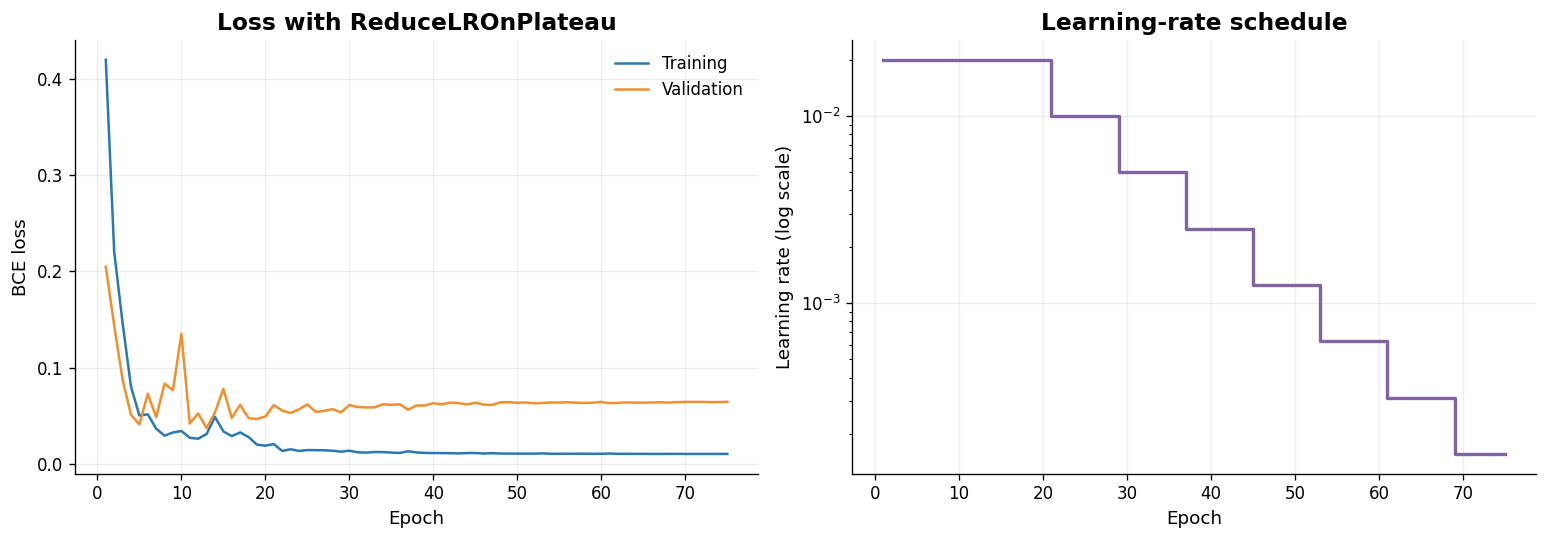

Final learning rate: 0.00015625


In [29]:
scheduler_model = BinaryClassifier(input_features=2).to(DEVICE)
scheduler_optimizer = torch.optim.Adam(scheduler_model.parameters(), lr=0.02)
lr_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    scheduler_optimizer, mode="min", factor=0.5, patience=7, min_lr=1e-4
)

scheduler_history = {"train_loss": [], "val_loss": [], "learning_rate": []}
SCHEDULER_EPOCHS = 75
for epoch in range(SCHEDULER_EPOCHS):
    train_loss_value, _ = train_one_epoch(scheduler_model, train_loader, criterion, scheduler_optimizer)
    val_loss_value, _ = evaluate(scheduler_model, X_val, y_val, criterion)
    lr_scheduler.step(val_loss_value)
    scheduler_history["train_loss"].append(train_loss_value)
    scheduler_history["val_loss"].append(val_loss_value)
    scheduler_history["learning_rate"].append(scheduler_optimizer.param_groups[0]["lr"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
epochs_axis = np.arange(1, SCHEDULER_EPOCHS + 1)
axes[0].plot(epochs_axis, scheduler_history["train_loss"], label="Training", color=COLORS["blue"])
axes[0].plot(epochs_axis, scheduler_history["val_loss"], label="Validation", color=COLORS["orange"])
axes[0].set_title("Loss with ReduceLROnPlateau")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE loss")
axes[0].legend()
axes[1].step(epochs_axis, scheduler_history["learning_rate"], where="post", color=COLORS["purple"], linewidth=2)
axes[1].set_yscale("log")
axes[1].set_title("Learning-rate schedule")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Learning rate (log scale)")
fig.tight_layout()
plt.show()
print("Final learning rate:", scheduler_history["learning_rate"][-1])

## 30. Compare network capacity

A wider hidden layer can represent more complex functions, but it also increases parameter count and may overfit. This experiment compares a few widths using the same split and a fixed training budget. Treat the validation results as an experiment, not a universal rule.

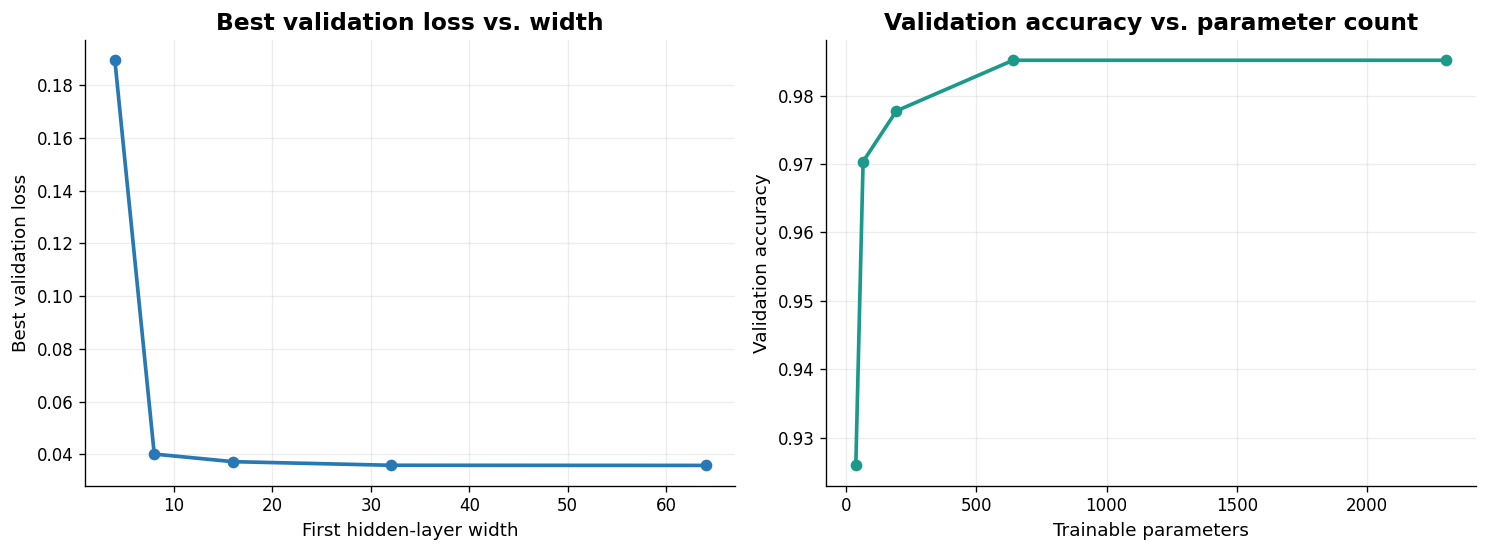

Width | Parameters | Best val loss | Val accuracy
    4 |         37 |        0.1895 |        0.926
    8 |         65 |        0.0401 |        0.970
   16 |        193 |        0.0372 |        0.978
   32 |        641 |        0.0358 |        0.985
   64 |       2305 |        0.0358 |        0.985


In [30]:
width_results = []
WIDTH_EPOCHS = 45
for width in [4, 8, 16, 32, 64]:
    width_model = BinaryClassifier(input_features=2, hidden_1=width, hidden_2=max(4, width // 2)).to(DEVICE)
    width_optimizer = torch.optim.Adam(width_model.parameters(), lr=0.01)
    best_width_val_loss = float("inf")
    best_width_accuracy = 0.0
    for epoch in range(WIDTH_EPOCHS):
        train_one_epoch(width_model, train_loader, criterion, width_optimizer)
        current_val_loss, current_val_accuracy = evaluate(width_model, X_val, y_val, criterion)
        if current_val_loss < best_width_val_loss:
            best_width_val_loss = current_val_loss
            best_width_accuracy = current_val_accuracy
    param_total = sum(p.numel() for p in width_model.parameters() if p.requires_grad)
    width_results.append((width, param_total, best_width_val_loss, best_width_accuracy))

width_array = np.asarray(width_results, dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7))
axes[0].plot(width_array[:, 0], width_array[:, 2], marker="o", linewidth=2.2, color=COLORS["blue"])
axes[0].set_title("Best validation loss vs. width")
axes[0].set_xlabel("First hidden-layer width")
axes[0].set_ylabel("Best validation loss")
axes[1].plot(width_array[:, 1], width_array[:, 3], marker="o", linewidth=2.2, color=COLORS["teal"])
axes[1].set_title("Validation accuracy vs. parameter count")
axes[1].set_xlabel("Trainable parameters")
axes[1].set_ylabel("Validation accuracy")
fig.tight_layout()
plt.show()
print("Width | Parameters | Best val loss | Val accuracy")
for width, params, val_loss_value, val_acc in width_results:
    print(f"{width:5d} | {params:10d} | {val_loss_value:13.4f} | {val_acc:12.3f}")

## 31. Tune the classification threshold on validation data

A probability threshold of `0.5` is common, but not always optimal. Select a threshold using validation predictions only. Then apply that fixed threshold once to the held-out test set.

Selected validation threshold: 0.490
Validation F1 at selected threshold: 0.993


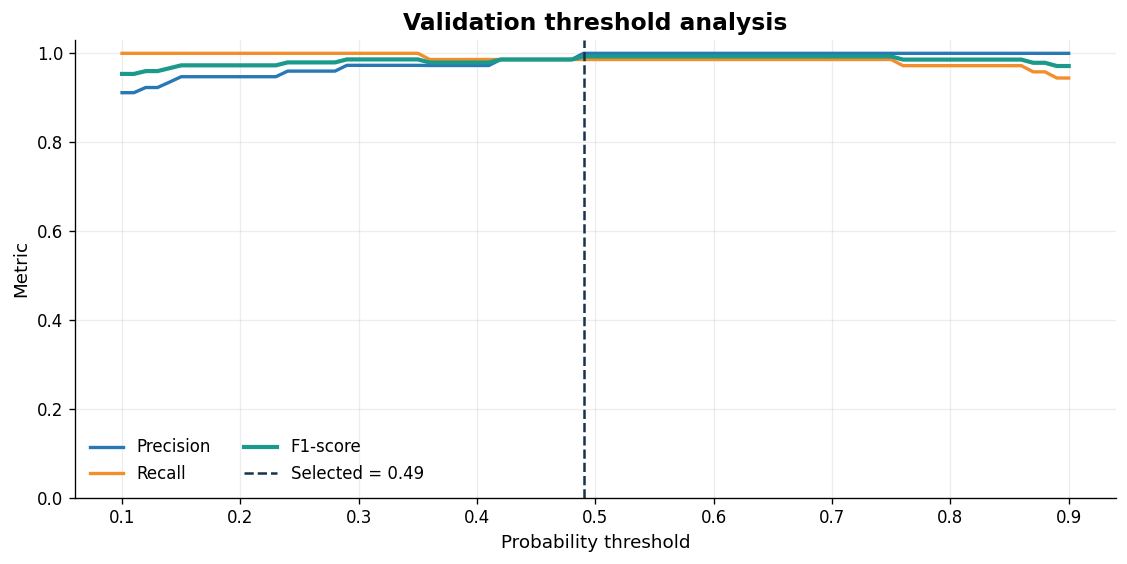

Test accuracy using validation-selected threshold: 1.000


In [31]:
model.eval()
with torch.inference_mode():
    val_probabilities = torch.sigmoid(model(X_val.to(DEVICE))).cpu().numpy()
val_targets_np = y_val.numpy().astype(int)

threshold_grid = np.linspace(0.10, 0.90, 81)
threshold_metrics = []
for threshold in threshold_grid:
    val_pred = (val_probabilities >= threshold).astype(int)
    tp_v = np.sum((val_pred == 1) & (val_targets_np == 1))
    fp_v = np.sum((val_pred == 1) & (val_targets_np == 0))
    fn_v = np.sum((val_pred == 0) & (val_targets_np == 1))
    precision_v = tp_v / max(tp_v + fp_v, 1)
    recall_v = tp_v / max(tp_v + fn_v, 1)
    f1_v = 2 * precision_v * recall_v / max(precision_v + recall_v, 1e-12)
    threshold_metrics.append((threshold, precision_v, recall_v, f1_v))

threshold_metrics = np.asarray(threshold_metrics)
best_threshold_idx = int(np.argmax(threshold_metrics[:, 3]))
selected_threshold = float(threshold_metrics[best_threshold_idx, 0])
print(f"Selected validation threshold: {selected_threshold:.3f}")
print(f"Validation F1 at selected threshold: {threshold_metrics[best_threshold_idx, 3]:.3f}")

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.plot(threshold_grid, threshold_metrics[:, 1], label="Precision", color=COLORS["blue"], linewidth=2)
ax.plot(threshold_grid, threshold_metrics[:, 2], label="Recall", color=COLORS["orange"], linewidth=2)
ax.plot(threshold_grid, threshold_metrics[:, 3], label="F1-score", color=COLORS["teal"], linewidth=2.5)
ax.axvline(selected_threshold, linestyle="--", color=COLORS["navy"], label=f"Selected = {selected_threshold:.2f}")
ax.set_xlabel("Probability threshold")
ax.set_ylabel("Metric")
ax.set_ylim(0, 1.03)
ax.set_title("Validation threshold analysis")
ax.legend(ncol=2)
fig.tight_layout()
plt.show()

threshold_test_predictions = (test_probabilities >= selected_threshold).astype(int)
threshold_test_accuracy = np.mean(threshold_test_predictions == test_targets)
print(f"Test accuracy using validation-selected threshold: {threshold_test_accuracy:.3f}")

## 32. Inspect confidence and probability calibration

A classifier can be accurate while its probabilities are poorly calibrated. This simple reliability diagram groups test predictions into confidence bins and compares average confidence with observed accuracy. Small bins can be noisy, especially on small datasets.

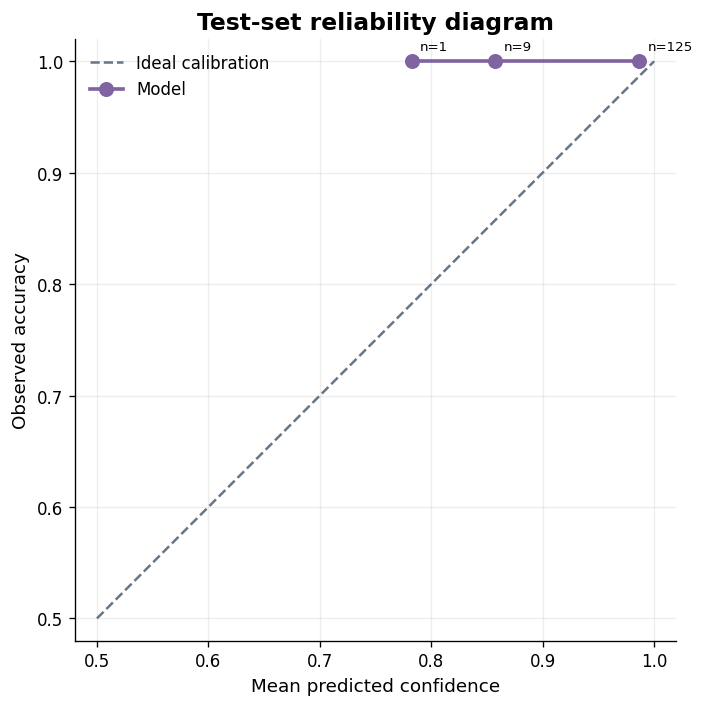

In [32]:
confidence = np.maximum(test_probabilities, 1 - test_probabilities)
correctness = (test_predictions == test_targets).astype(float)
confidence_edges = np.linspace(0.5, 1.0, 6)
bin_centers, bin_confidence, bin_accuracy, bin_counts = [], [], [], []
for left, right in zip(confidence_edges[:-1], confidence_edges[1:]):
    mask = (confidence >= left) & (confidence < right if right < 1.0 else confidence <= right)
    if mask.any():
        bin_centers.append((left + right) / 2)
        bin_confidence.append(confidence[mask].mean())
        bin_accuracy.append(correctness[mask].mean())
        bin_counts.append(mask.sum())

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0.5, 1.0], [0.5, 1.0], linestyle="--", color=COLORS["gray"], label="Ideal calibration")
ax.plot(bin_confidence, bin_accuracy, marker="o", markersize=8, linewidth=2.2, color=COLORS["purple"], label="Model")
for x_value, y_value, count in zip(bin_confidence, bin_accuracy, bin_counts):
    ax.annotate(f"n={count}", (x_value, y_value), xytext=(5, 7), textcoords="offset points", fontsize=8)
ax.set_xlim(0.48, 1.02)
ax.set_ylim(0.48, 1.02)
ax.set_xlabel("Mean predicted confidence")
ax.set_ylabel("Observed accuracy")
ax.set_title("Test-set reliability diagram")
ax.legend()
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
plt.show()

## 33. Perform visual error analysis

The next plot distinguishes correct and incorrect test predictions in feature space. Error analysis is often more informative than looking at a single accuracy score because it reveals where the model struggles.

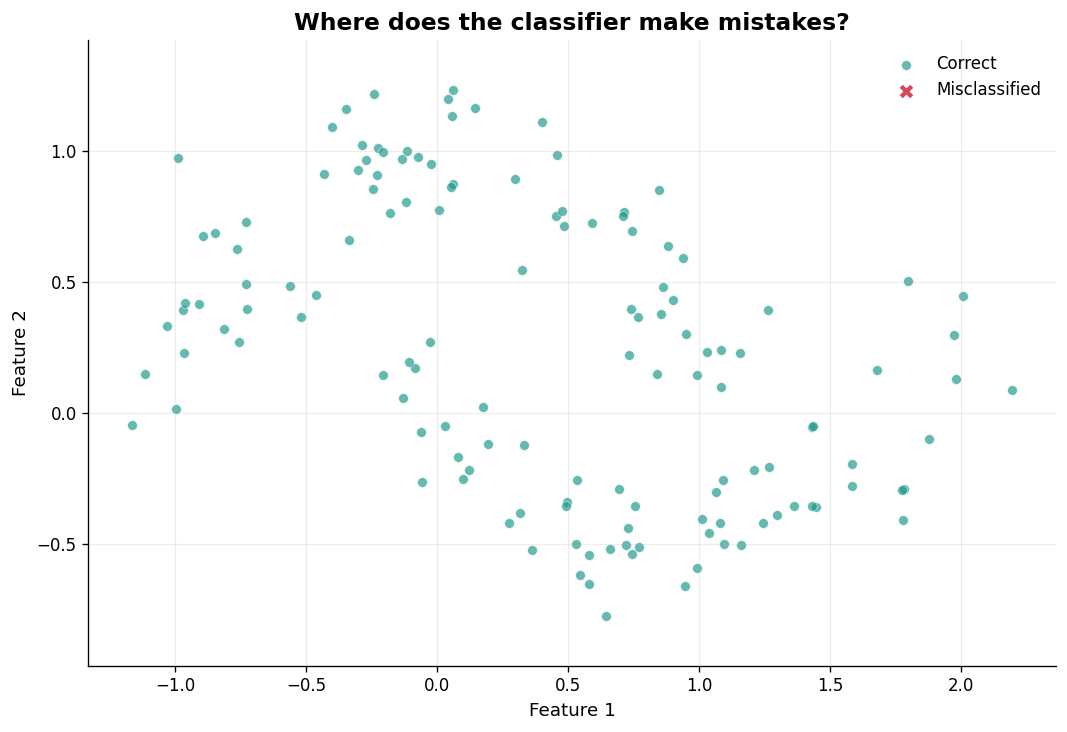

Correct predictions    : 135
Misclassified examples : 0


In [33]:
test_features_np = X_test.numpy()
misclassified_mask = test_predictions != test_targets
correct_mask = ~misclassified_mask

fig, ax = plt.subplots(figsize=(9, 6.2))
ax.scatter(test_features_np[correct_mask, 0], test_features_np[correct_mask, 1],
           c=COLORS["teal"], s=34, alpha=0.68, label="Correct", edgecolors="white", linewidths=0.4)
ax.scatter(test_features_np[misclassified_mask, 0], test_features_np[misclassified_mask, 1],
           c=COLORS["red"], s=78, marker="X", label="Misclassified", edgecolors="white", linewidths=0.5)
ax.set_title("Where does the classifier make mistakes?")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
plt.show()
print(f"Correct predictions    : {correct_mask.sum()}")
print(f"Misclassified examples : {misclassified_mask.sum()}")

## 34. Inspect the most uncertain predictions

For binary classification, probabilities close to `0.5` indicate low confidence. The examples below are sorted by distance from `0.5`, smallest first. This is a useful starting point for reviewing ambiguous examples.

In [34]:
uncertainty_scores = np.abs(test_probabilities - 0.5)
uncertain_order = np.argsort(uncertainty_scores)[:min(12, len(test_probabilities))]
print(" idx | feature 1 | feature 2 | true | probability(class 1) | predicted | distance from 0.5")
print("-" * 91)
for idx in uncertain_order:
    x1, x2 = test_features_np[idx]
    print(f"{idx:4d} | {x1:9.3f} | {x2:9.3f} | {test_targets[idx]:4d} | {test_probabilities[idx]:19.3f} | {test_predictions[idx]:9d} | {uncertainty_scores[idx]:17.3f}")

 idx | feature 1 | feature 2 | true | probability(class 1) | predicted | distance from 0.5
-------------------------------------------------------------------------------------------
   5 |     0.325 |     0.545 |    0 |               0.218 |         0 |             0.282
 102 |     0.733 |     0.221 |    0 |               0.167 |         0 |             0.333
  97 |     1.083 |     0.099 |    0 |               0.165 |         0 |             0.335
  12 |     1.264 |     0.392 |    0 |               0.162 |         0 |             0.338
  21 |     1.156 |     0.229 |    0 |               0.153 |         0 |             0.347
  79 |    -0.181 |     0.762 |    0 |               0.146 |         0 |             0.354
  25 |     0.838 |     0.150 |    0 |               0.137 |         0 |             0.363
  23 |     0.008 |     0.773 |    0 |               0.134 |         0 |             0.366
  37 |    -0.118 |     0.804 |    0 |               0.112 |         0 |             0.388
  56 | 

## 35. Demonstrate gradient clipping

Gradient clipping limits unusually large gradients before the optimizer update. It is often used in recurrent networks and deep models. Here we measure the gradient norm before and after clipping on a single batch.

In [35]:
clip_model = BinaryClassifier(input_features=2).to(DEVICE)
clip_optimizer = torch.optim.Adam(clip_model.parameters(), lr=0.01)
clip_features, clip_targets = next(iter(train_loader))
clip_features, clip_targets = clip_features.to(DEVICE), clip_targets.to(DEVICE)

clip_optimizer.zero_grad(set_to_none=True)
clip_logits = clip_model(clip_features)
clip_loss = criterion(clip_logits, clip_targets)
clip_loss.backward()

pre_clip_norm = torch.nn.utils.clip_grad_norm_(clip_model.parameters(), max_norm=0.10)
post_clip_norm = torch.sqrt(sum((p.grad.detach() ** 2).sum() for p in clip_model.parameters() if p.grad is not None)).item()
clip_optimizer.step()
print(f"Gradient norm before clipping: {float(pre_clip_norm):.6f}")
print(f"Gradient norm after clipping : {post_clip_norm:.6f}")
print("The optimizer step above uses clipped gradients.")

Gradient norm before clipping: 0.344541
Gradient norm after clipping : 0.100000
The optimizer step above uses clipped gradients.


## 36. Build a variable-depth network with `nn.ModuleList`

`nn.ModuleList` registers a Python list of submodules so that their parameters are visible to PyTorch. Unlike an ordinary Python list, its modules are included in `.parameters()` and `.state_dict()`. The forward pass is written explicitly.

In [36]:
class VariableDepthClassifier(nn.Module):
    def __init__(self, input_features: int, hidden_width: int, depth: int):
        super().__init__()
        if depth < 1:
            raise ValueError("depth must be at least 1")
        self.input_layer = nn.Linear(input_features, hidden_width)
        self.hidden_layers = nn.ModuleList(
            [nn.Linear(hidden_width, hidden_width) for _ in range(depth - 1)]
        )
        self.output_layer = nn.Linear(hidden_width, 1)

    def forward(self, x):
        x = torch.relu(self.input_layer(x))
        for layer in self.hidden_layers:
            x = torch.relu(layer(x))
        return self.output_layer(x).squeeze(1)

variable_depth_model = VariableDepthClassifier(input_features=2, hidden_width=24, depth=4).to(DEVICE)
with torch.inference_mode():
    variable_depth_output = variable_depth_model(X_train[:10].to(DEVICE))
print(variable_depth_model)
print("Output shape:", tuple(variable_depth_output.shape))
print("Registered hidden layers:", len(variable_depth_model.hidden_layers))
print("State dict includes:", [key for key in variable_depth_model.state_dict() if "hidden_layers" in key][:4])

VariableDepthClassifier(
  (input_layer): Linear(in_features=2, out_features=24, bias=True)
  (hidden_layers): ModuleList(
    (0-2): 3 x Linear(in_features=24, out_features=24, bias=True)
  )
  (output_layer): Linear(in_features=24, out_features=1, bias=True)
)
Output shape: (10,)
Registered hidden layers: 3
State dict includes: ['hidden_layers.0.weight', 'hidden_layers.0.bias', 'hidden_layers.1.weight', 'hidden_layers.1.bias']


## 37. Use a reusable mini-batch inference function

Inference helpers should handle evaluation mode, gradient disabling, and device movement consistently. This helper accepts either a tensor or an array-like input and returns probabilities on the CPU.

In [37]:
@torch.inference_mode()
def predict_probabilities(model_to_use: nn.Module, features, batch_size: int = 256) -> torch.Tensor:
    """Return sigmoid probabilities on CPU, preserving row order."""
    model_to_use.eval()
    feature_tensor = torch.as_tensor(features, dtype=torch.float32)
    if feature_tensor.ndim == 1:
        feature_tensor = feature_tensor.unsqueeze(0)
    if feature_tensor.ndim != 2:
        raise ValueError("features must have shape [n_samples, n_features]")

    outputs = []
    for start in range(0, len(feature_tensor), batch_size):
        batch = feature_tensor[start:start + batch_size].to(DEVICE)
        logits = model_to_use(batch)
        outputs.append(torch.sigmoid(logits).cpu())
    return torch.cat(outputs, dim=0) if outputs else torch.empty(0)

batch_predictions = predict_probabilities(model, X_test, batch_size=48)
print("Probability tensor shape:", tuple(batch_predictions.shape))
print("First 8 probabilities   :", batch_predictions[:8].numpy().round(3))
print("Predictions in [0, 1]   :", bool(((batch_predictions >= 0) & (batch_predictions <= 1)).all()))

Probability tensor shape: (135,)
First 8 probabilities   : [0.031 0.045 0.985 0.008 0.993 0.218 0.998 0.021]
Predictions in [0, 1]   : True


## 38. Save plots and predictions as reusable project artifacts

A notebook is useful for exploration, but saved artifacts make results easier to reuse in reports and project repositories. This cell creates a local output directory, saves a figure, and exports test predictions as a CSV file using NumPy only.

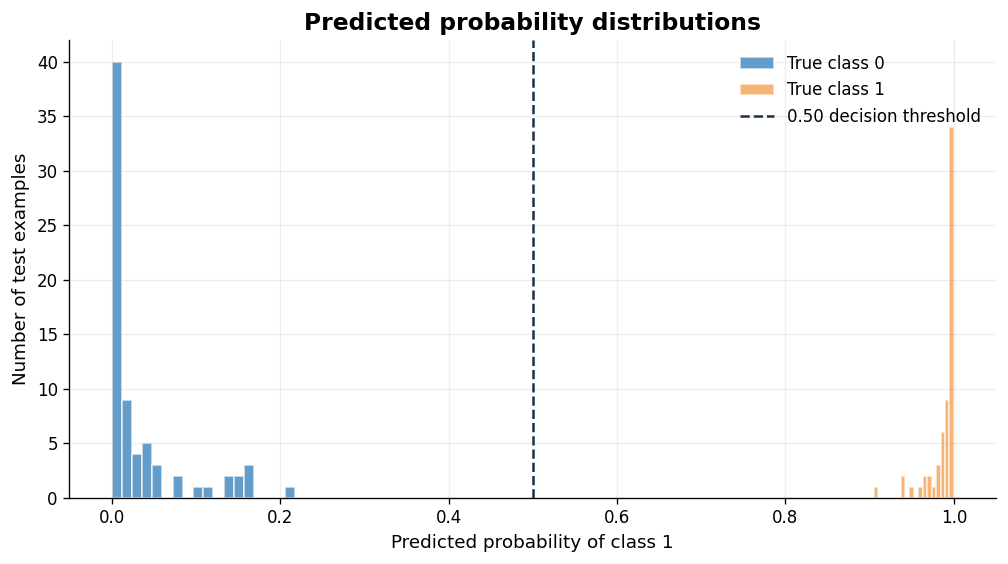

Saved prediction file: /content/pytorch_nn_module_outputs/test_predictions.csv
Saved figure        : /content/pytorch_nn_module_outputs/figures/test_probability_distribution.png


In [38]:
from pathlib import Path

OUTPUT_DIR = Path("pytorch_nn_module_outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

# Export a compact prediction table: features, true label, probability, predicted label.
prediction_export = np.column_stack([
    test_features_np,
    test_targets,
    test_probabilities,
    test_predictions,
])
export_path = OUTPUT_DIR / "test_predictions.csv"
np.savetxt(
    export_path,
    prediction_export,
    delimiter=",",
    header="feature_1,feature_2,true_label,probability_class_1,predicted_label",
    comments="",
    fmt=["%.6f", "%.6f", "%d", "%.6f", "%d"],
)

# Create and save a report-ready score plot.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(test_probabilities[test_targets == 0], bins=18, alpha=0.72, label="True class 0", color=COLORS["blue"], edgecolor="white")
ax.hist(test_probabilities[test_targets == 1], bins=18, alpha=0.65, label="True class 1", color=COLORS["orange"], edgecolor="white")
ax.axvline(0.5, linestyle="--", color=COLORS["navy"], label="0.50 decision threshold")
ax.set_title("Predicted probability distributions")
ax.set_xlabel("Predicted probability of class 1")
ax.set_ylabel("Number of test examples")
ax.legend()
fig.tight_layout()
probability_plot_path = FIGURE_DIR / "test_probability_distribution.png"
fig.savefig(probability_plot_path, bbox_inches="tight")
plt.show()

print("Saved prediction file:", export_path.resolve())
print("Saved figure        :", probability_plot_path.resolve())

## 39. Final checklist and practical extensions

Before using a custom `nn.Module` in a real project, confirm the following:

1. Subclasses call `super().__init__()` and define layers in `__init__()`.
2. `forward()` returns the intended shape and raw logits when using `BCEWithLogitsLoss`.
3. Inputs and targets have compatible shapes, dtypes, and devices.
4. Training uses `model.train()`; validation and inference use `model.eval()` with no gradient tracking.
5. Hyperparameters and thresholds are selected without using the test set.
6. Saved checkpoints include enough information to reconstruct the architecture.
7. Every experiment is reproducible and its outputs are clearly labeled.

**Further experiments:** replace the synthetic dataset with a real tabular dataset, add feature scaling, compare `AdamW`, introduce weight decay, or implement multiclass classification with `nn.CrossEntropyLoss`.

## 40. Key takeaways

- `nn.Module` is the foundation for custom PyTorch models.
- Define model components in `__init__()` and the forward computation in `forward()`.
- Use `model(x)` for the forward pass and inspect registered weights with `named_parameters()`.
- Match the model output and loss function: raw logits pair naturally with `BCEWithLogitsLoss`.
- A reliable training loop clears gradients, computes loss, backpropagates, and updates parameters.
- Validation curves help diagnose generalization; the held-out test set gives a final evaluation.
- Visual diagnostics reveal behavior that a single accuracy score cannot show.
- Save learned parameters with `state_dict`, then recreate the architecture when reloading.

### Suggested next step

Extend this notebook with a multiclass classifier using `nn.CrossEntropyLoss`, then build a small project with a real dataset and a documented experiment log.

---

**End of notebook · PyTorch `nn.Module` learning module**

The additional labs above deepen the core lesson: `nn.Module` is more than a container for layers—it is the mechanism PyTorch uses to register parameters, compose components, manage model state, and support the complete training and inference lifecycle.